# Tree Segmentation - Marker-Controlled Watershed

Same CHM, smoothing, treetops (`lmf`) and over-segmentation diagnostics as `tree_segmentation_dalponte.ipynb`, but crowns are delineated with a **marker-controlled watershed** (`ForestTools::mcws`). Dalponte is also run so the two can be compared directly.

## How the watershed works
Flip the CHM upside down: each tree crown becomes a basin and the valleys between crowns become ridges. Starting from each treetop (the **marker**), the basin floods outward until it meets the flood from a neighbouring marker; the meeting line is the crown boundary. Cells below `min_height` are masked out, so ground between tree rows is not assigned to any tree.

## Should you use it? Yes as a comparison, probably not as a replacement

**For an orchard it is a good fit:** crowns are isolated or only slightly touching, roughly round, evenly spaced, and surrounded by low ground. Boundaries between touching crowns follow the actual valley in the CHM instead of a height-ratio rule, and there are no growth thresholds to tune.

**Caveats**
- It is only as good as the markers. The same `lmf` treetops go in, so watershed will **not fix over-segmentation** - a double top gives two basins.
- Every above-threshold cell is assigned to *some* tree, so crowns are larger (include the soft edge) than Dalponte's, which stops at `th_cr`. Crown area/diameter are biased high unless `min_height` is well above the ground/weed layer.
- Basins can leak into neighbouring weeds or cover crop if `min_height` is too low.
- For your downstream use (per-tree height, count per footprint), heights come from the treetops, so **the choice between watershed and Dalponte barely changes the biomass inputs**; it matters for crown area, crown diameter, and the over-segmentation checks.

Refs: Hyyppa et al. 2001 and Chen et al. 2006 (marker-controlled watershed on a CHM); [fruit-tree crown extraction with local maximum + marker-controlled watershed](https://www.sciencedirect.com/science/article/pii/S2666719322000644).

## 1. Packages

In [1]:
# install.packages(c("terra", "sf", "lidR", "dplyr", "ForestTools", "igraph"))   # igraph is needed by mcws
suppressPackageStartupMessages({ library(terra); library(sf); library(lidR); library(dplyr); library(ForestTools) })
source("../scripts/segmentation_helpers.R")   # crown stats + over-segmentation diagnostics + plots

## 2. Configuration

In [2]:
cfg <- list(
  res        = "0.5m",   # CHM resolution to use: "0.5m" (recommended) or "0.25m" (sensitivity check)
  smooth_k   = 3,        # median smoothing kernel (cells). 3x3 @0.5 m = 1.5 m
  lmf_ws     = 4.25,     # local-maximum window (m): ~ half a typical crown diameter
  min_height = 1.5,      # ignore anything below this (m): ground, weeds, cover crop
  max_height = 7,        # ignore anything above this (m): wind turbines, tall eucalyptus
  # Dalponte settings (only used for the comparison in section 7)
  th_tree    = 1.5,      # Dalponte: min height of any crown cell (m)
  th_seed    = 0.45,     # Dalponte: cell must be > th_seed x seed height
  th_cr      = 0.55,     # Dalponte: cell must be > th_cr x mean crown height
  max_cr_m   = 10,       # Dalponte: max crown extent (m) - converted to pixels below
  # over-segmentation diagnostics
  os_min_prom = 1.0,     # shorter top must rise >= this (m) above the saddle, else the pair is suspect
  os_max_dist = 4.0,     # ...only checked for tops closer than this (m)
  os_min_area = 3.0,     # crowns smaller than this (m2) are flagged as slivers
  # ground-truth comparison
  match_max_dist = 4,    # max distance (m) between a surveyed tree and its segmented treetop
  outlier_m      = 5,    # matches with |height error| >= this are also reported separately
  merge_max_prom = 0.16, # two treetops count as ONE tree if the shorter one sticks up less than this (m) above the dip between them
  merge_max_dist = 3.0   # ...and they are less than this (m) apart
)

## 3. Load CHM, smooth, detect treetops

In [3]:
# Paths are relative to the notebooks/ folder
chm_path <- sprintf("../../Rasters/bart_chm_%s_clipped.tif", cfg$res)
ground_path <- "../data/br_ground_trees_clipped_to_footprints.xlsx"
out_dir  <- file.path("../outputs/Bartleson Tree Segmentation", paste0("watershed_", cfg$res))
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

chm <- rast(chm_path)
chm[chm > cfg$max_height] <- NA
res_m <- res(chm)[1]
cat("CHM:", basename(chm_path), "| resolution:", res_m, "m\n")

# Smooth + detect treetops (shared by both segmentation methods)
chm_smooth <- focal(chm, w = matrix(1, cfg$smooth_k, cfg$smooth_k), fun = median, na.rm = TRUE)
ttops <- locate_trees(chm_smooth, lmf(ws = cfg$lmf_ws, hmin = cfg$min_height))
ttops$height <- st_coordinates(ttops)[, "Z"]
cat("Treetops detected:", nrow(ttops), "\n")

CHM: bart_chm_0.5m_clipped.tif | resolution: 0.5 m
Treetops detected: 4378 


## 4. Marker-controlled watershed

In [4]:
crowns <- mcws(treetops = ttops, CHM = chm_smooth, minHeight = cfg$min_height)   # SpatRaster of treeIDs
names(crowns) <- "treeID"
pairs0 <- adjacent_pairs(crowns, chm_smooth, ttops)                                       # 1. Find pairs of neighbouring crowns that touch
merge <- pairs0 |> filter(prominence < cfg$merge_max_prom, dist_m < cfg$merge_max_dist)   # 2. Keep only pairs that look like one tree with two bumps: tops very close together AND barely any dip between them
drop <- ifelse(merge$h_a < merge$h_b, merge$a, merge$b)                                   # 3. In each pair, mark the shorter top for removal
cat("Merging", length(unique(drop)), "double tops\n")
ttops <- ttops[!ttops$treeID %in% drop, ]                                                 # 4. Remove those tops and renumber the rest 1, 2, 3, ...
ttops$treeID <- seq_len(nrow(ttops))
crowns <- mcws(treetops = ttops, CHM = chm_smooth, minHeight = cfg$min_height)            # 5. Flood again, now that each tree has only one top
names(crowns) <- "treeID"

Merging 63 double tops


## 5. Over-segmentation diagnostics

In [5]:
polys <- crown_polygons(crowns, chm_smooth, ttops)
pairs <- adjacent_pairs(crowns, chm_smooth, ttops)
fl    <- flag_overseg(polys, pairs, cfg$os_min_prom, cfg$os_max_dist, cfg$os_min_area)
polys <- fl$polys; suspect_pairs <- fl$suspect_pairs

cat("Crowns:", nrow(polys), "| median crown diameter:", round(median(polys$diam_m), 2), "m\n")
print(table(polys$flag))
cat(sprintf("Suspect over-segmented pairs: %d  (%.1f%% of crowns involved)\n",
            nrow(suspect_pairs), 100 * mean(polys$in_suspect_pair)))

Crowns: 4315 | median crown diameter: 4.75 m

          ok  small crown suspect pair 
        3957           12          346 
Suspect over-segmented pairs: 178  (8.0% of crowns involved)


## 6. Visualization

Warning message in plot.sf(ttops, col = "red", add = TRUE, cex = 0.1):
"ignoring all but the first attribute"


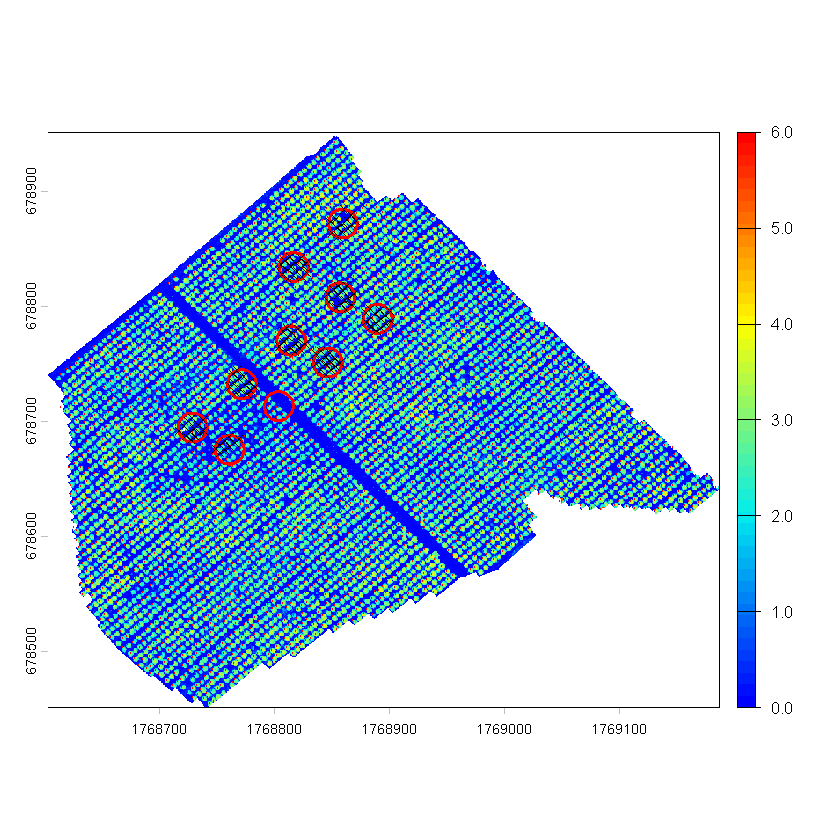

In [6]:
col <- height.colors(50)

footprints <- st_read("../../selected_v3_footprints_10.gpkg", quiet = TRUE) |> st_transform(st_crs(chm))
ground_vis <- read_ground_trees(ground_path, st_crs(chm))

plot(chm, range = c(0, 6), col = col)
plot(ttops, col = "red", add = TRUE, cex = 0.1)
plot(st_geometry(footprints), border = "red", col = NA, lwd = 3, add = TRUE)
plot(st_geometry(ground_vis), pch = 4, col = "black", cex = 0.8, add = TRUE)


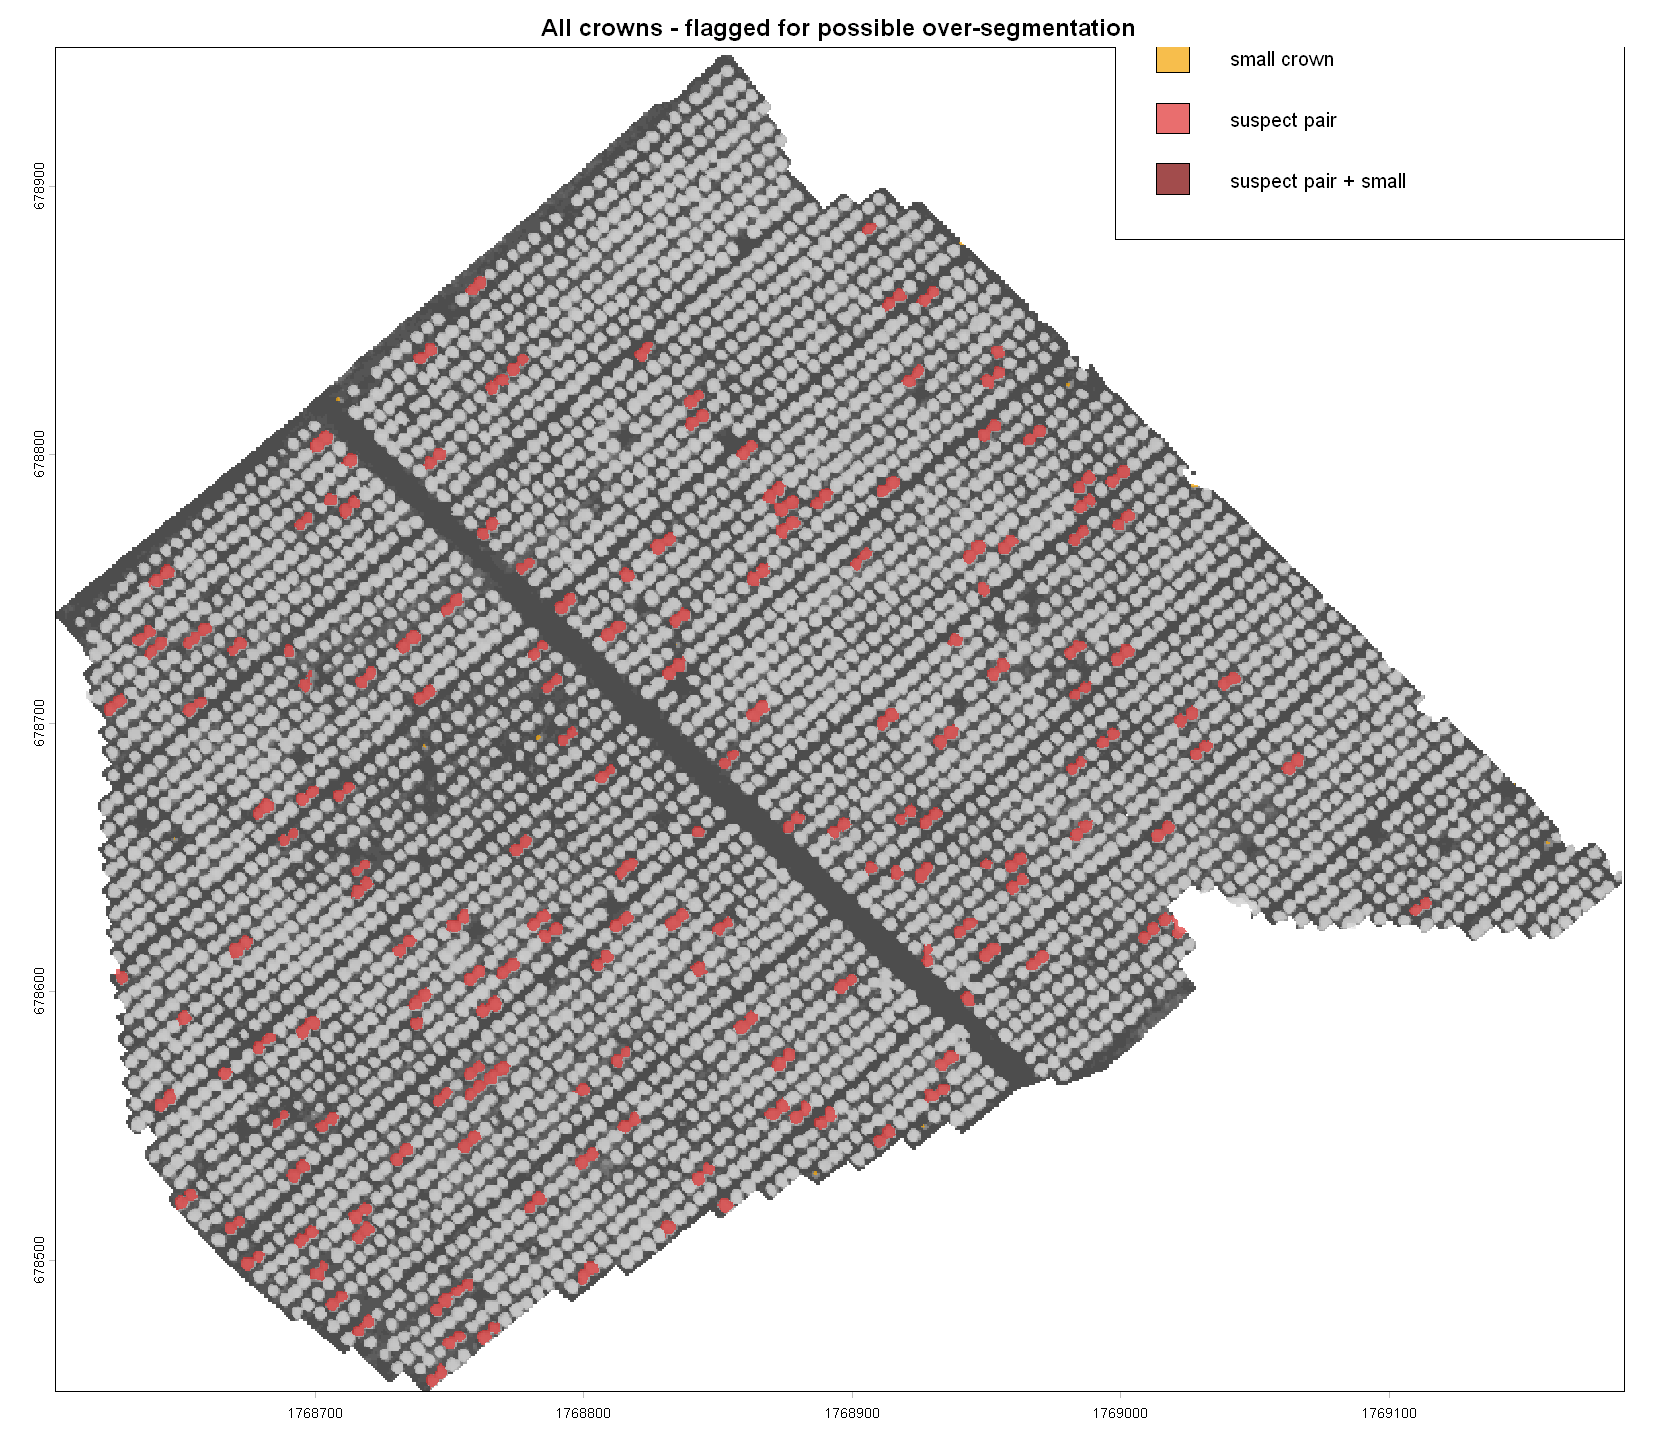

In [7]:
# Whole-scene map: crowns coloured by over-segmentation flag
options(repr.plot.width = 14, repr.plot.height = 12)
flag_cols <- c("ok" = "#cccccc", "small crown" = "#f4a300", "suspect pair" = "#e03131", "suspect pair + small" = "#7b0000")
plot(chm_smooth, col = gray.colors(50, 0.3, 1), legend = FALSE, main = "All crowns - flagged for possible over-segmentation")
plot(st_geometry(polys), col = adjustcolor(flag_cols[polys$flag], 0.7), border = NA, add = TRUE)
legend("topright", legend = names(flag_cols), fill = adjustcolor(flag_cols, 0.7), bg = "white")

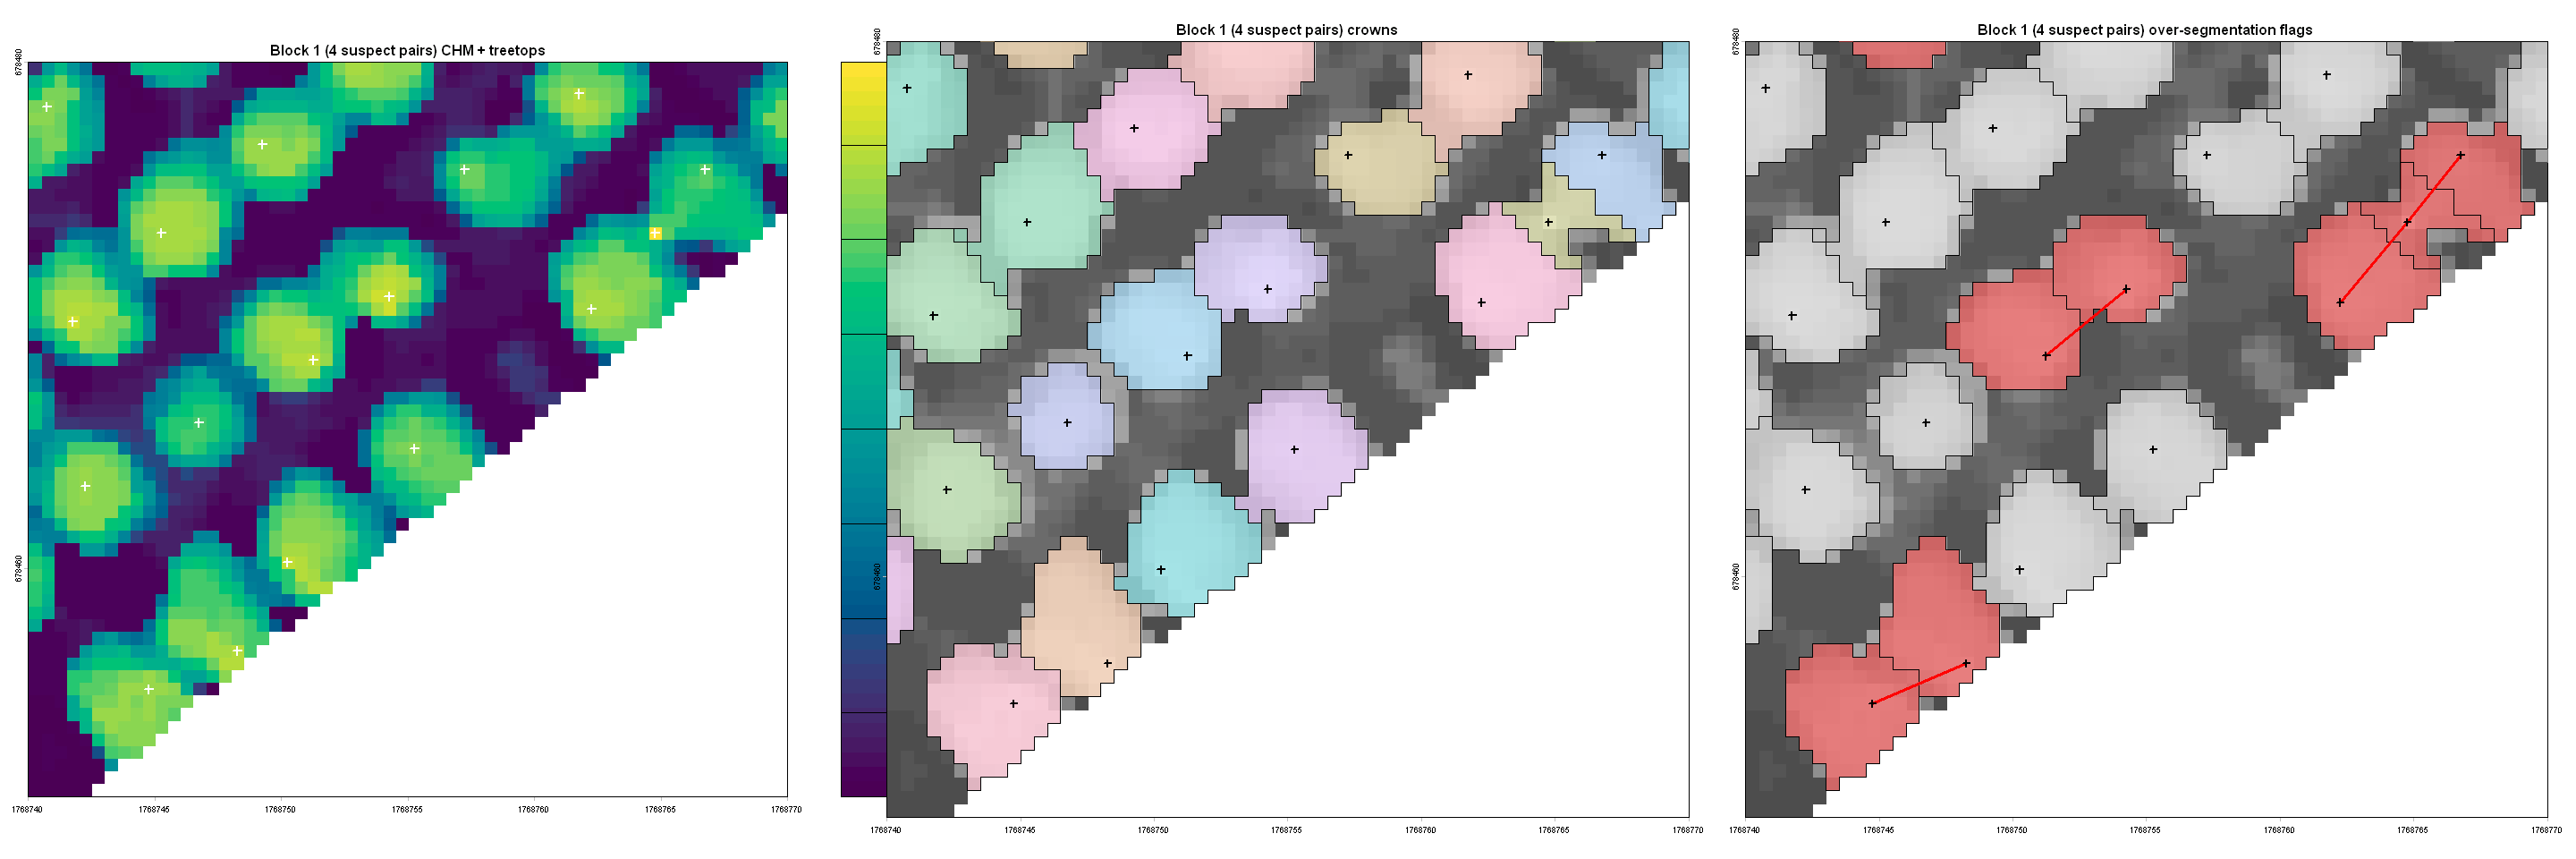

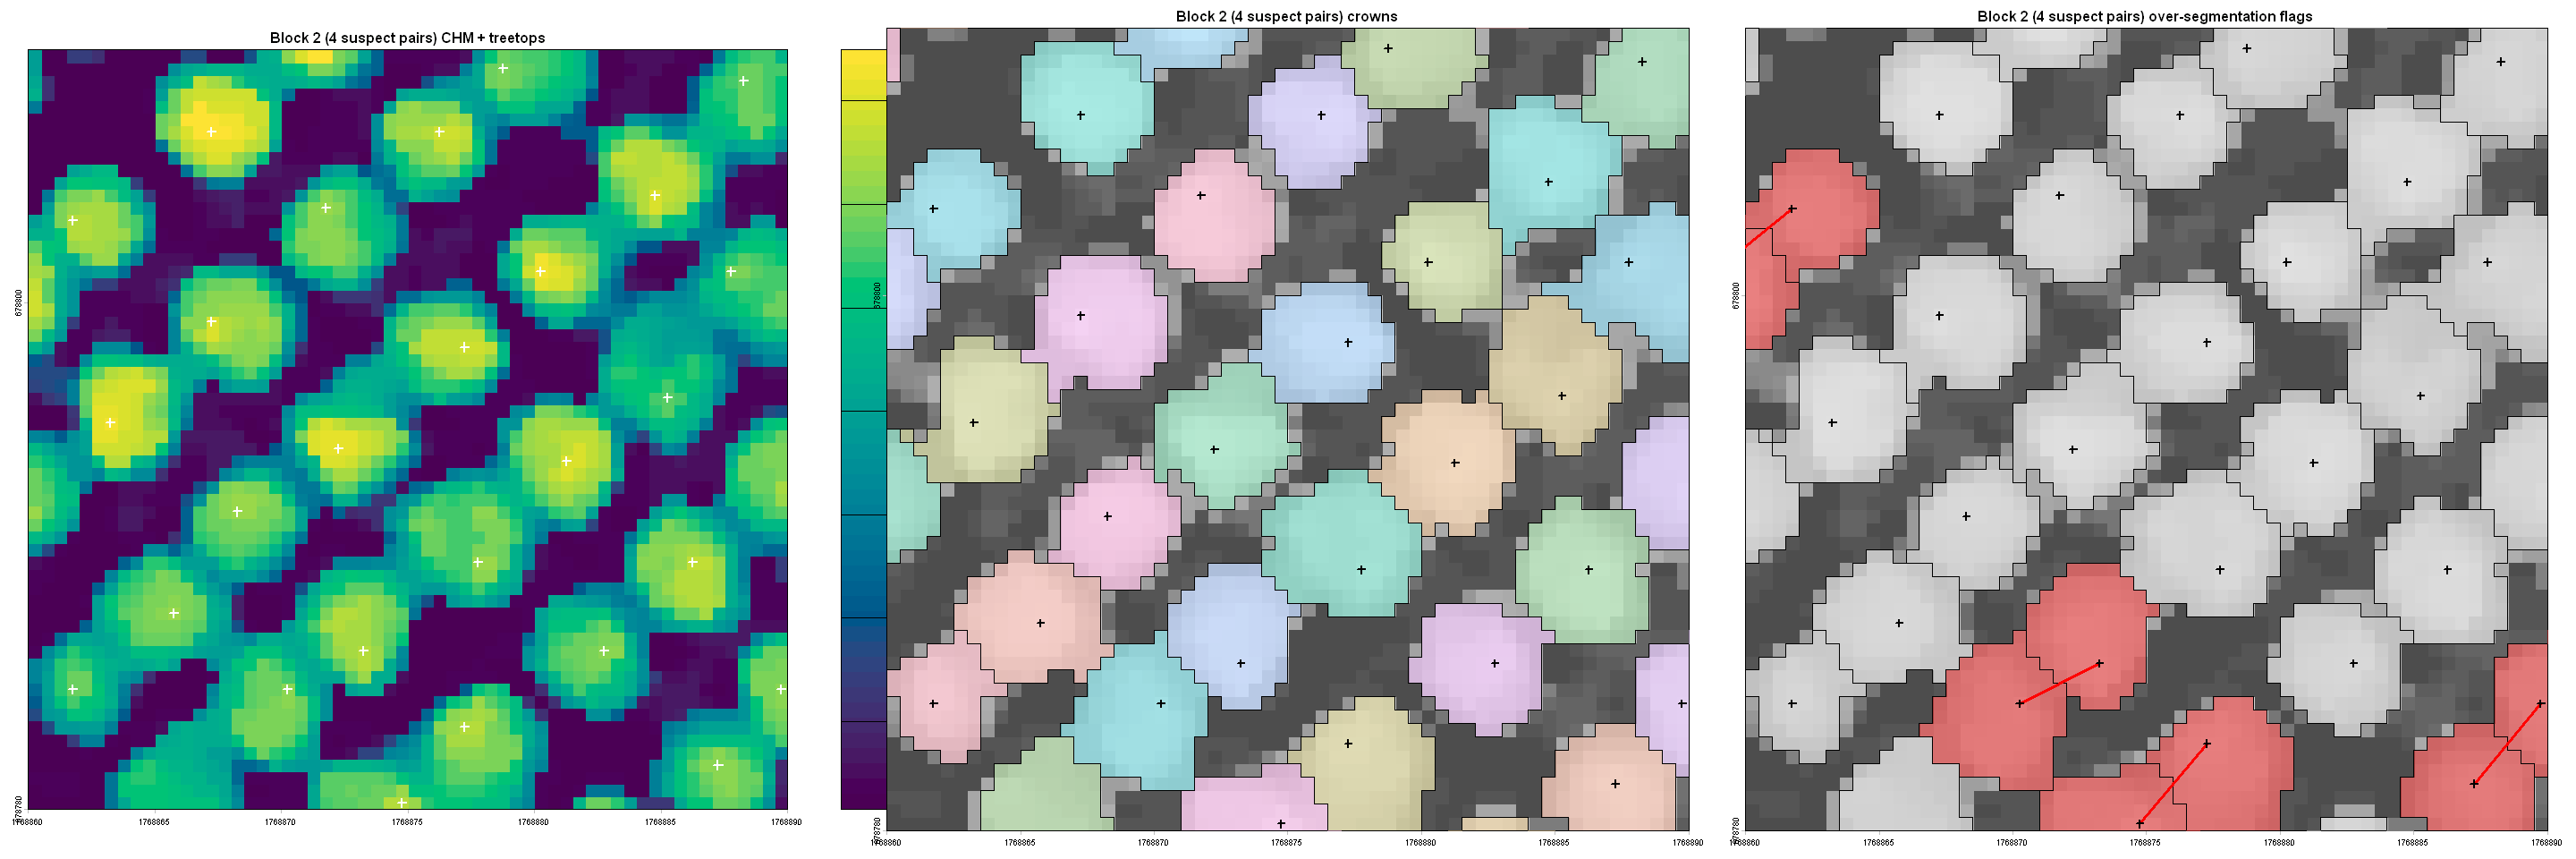

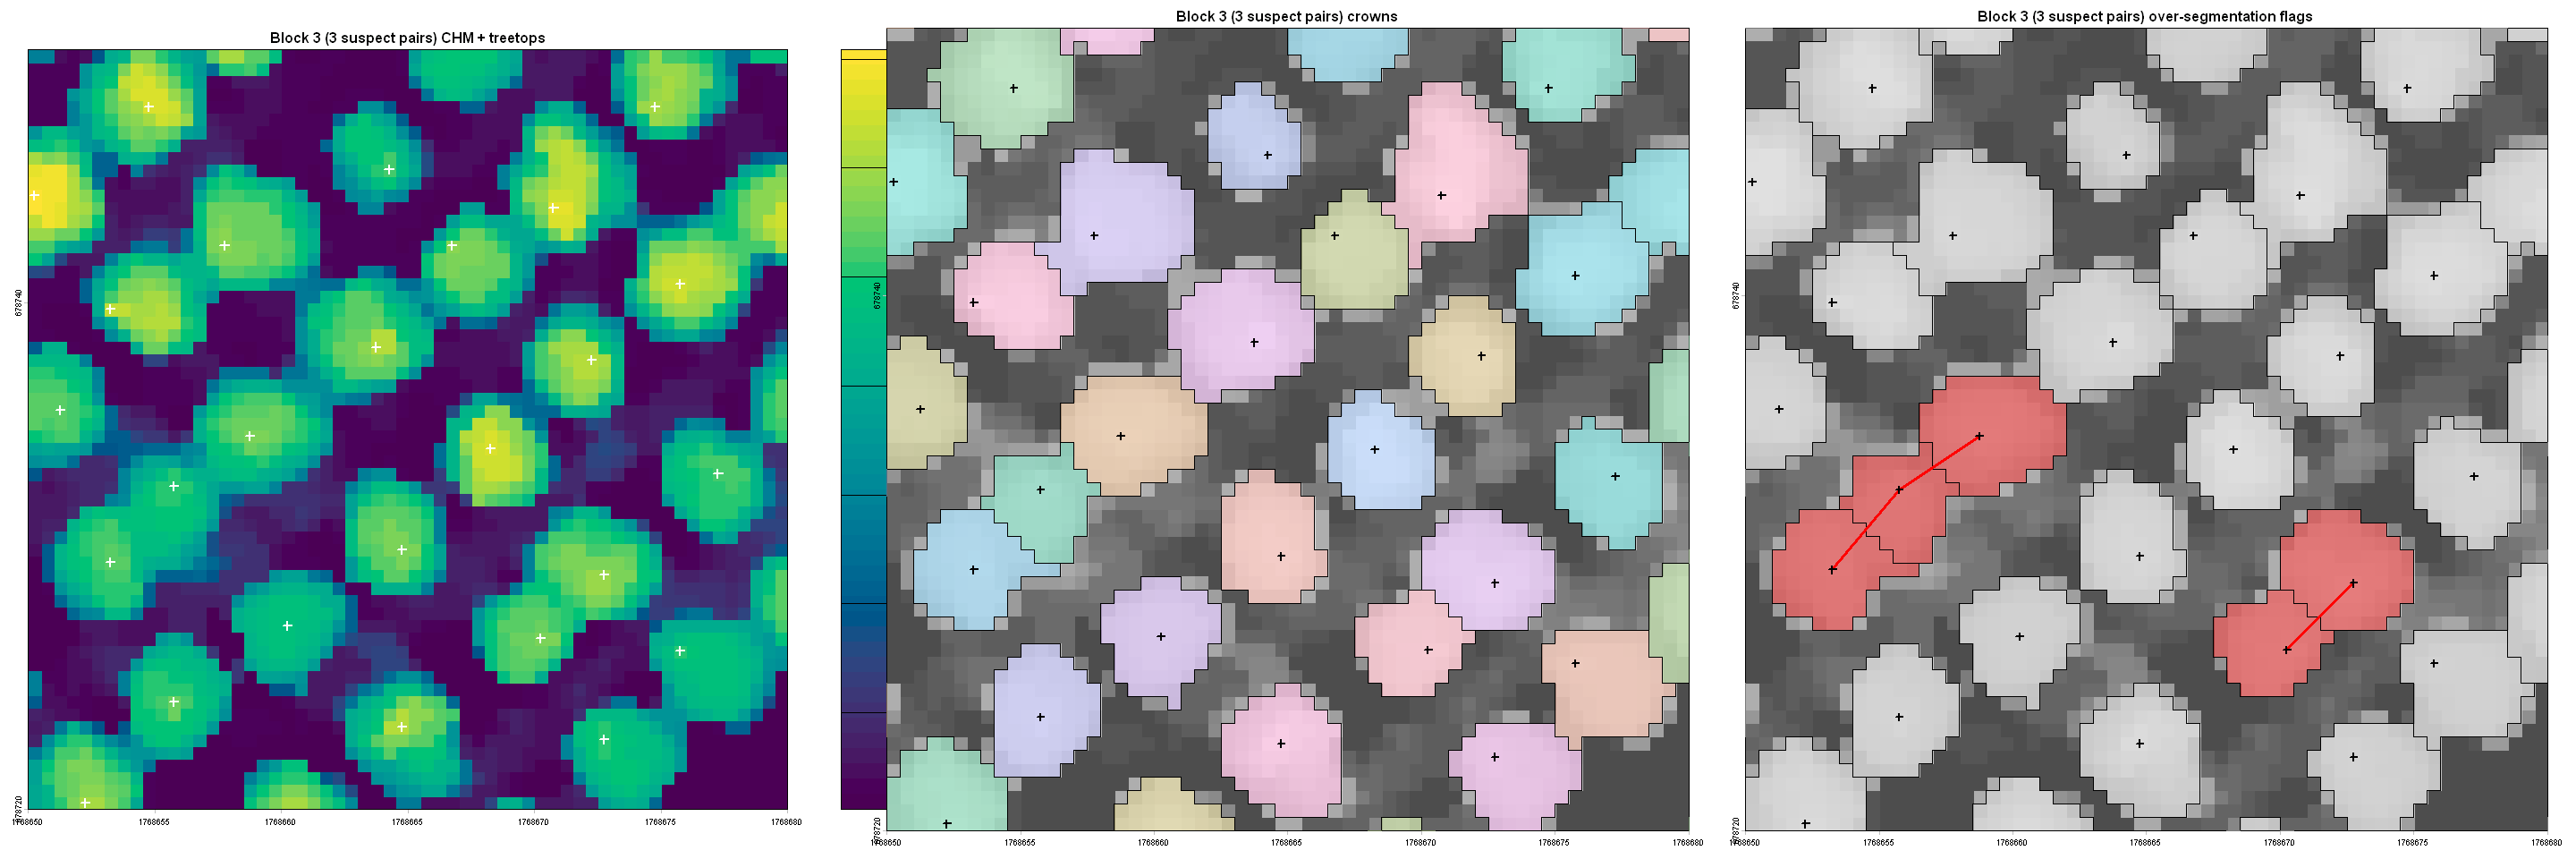

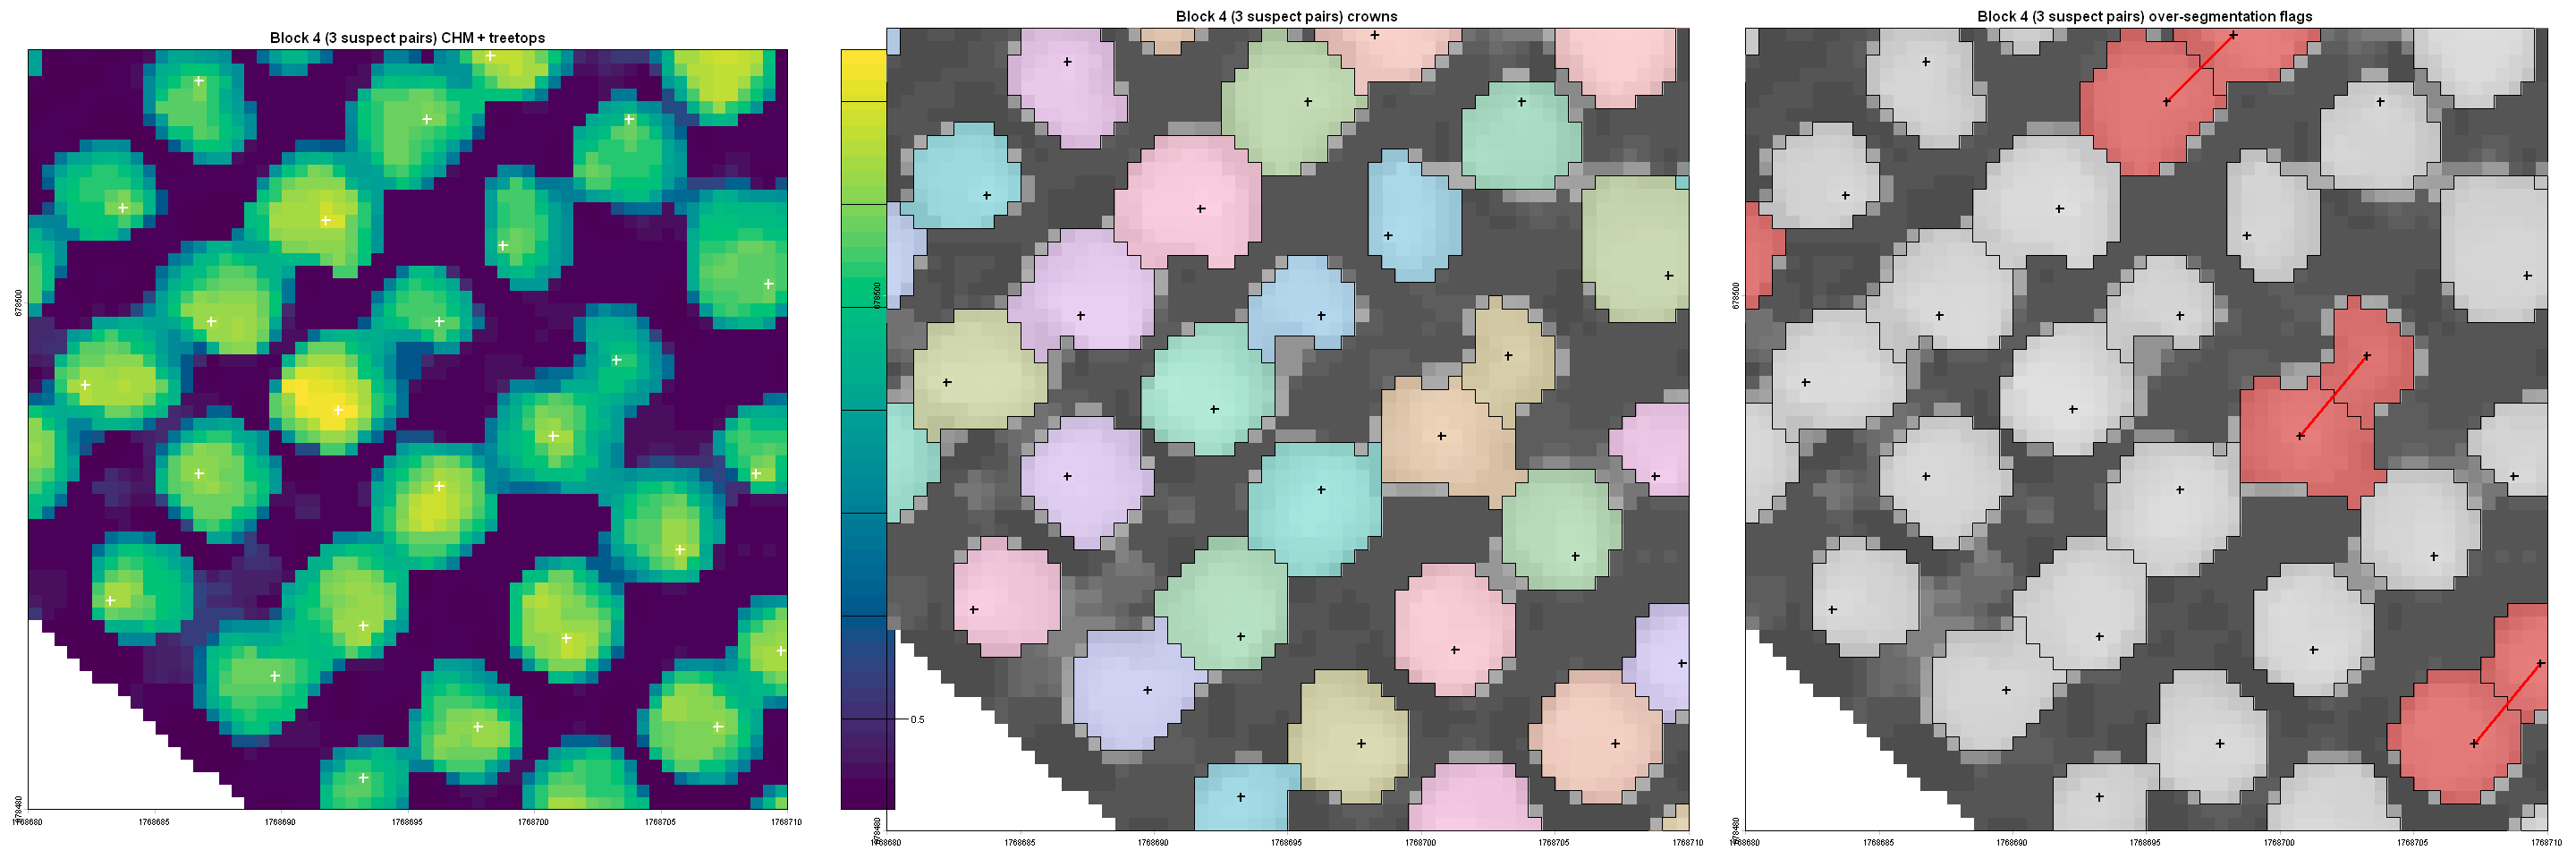

In [8]:
options(repr.plot.width = 24, repr.plot.height = 8)

# The 4 most over-segmented 30 m blocks in the scene: CHM+tops | crowns | flags
blk <- suspect_pairs |>
  mutate(bx = floor((xa + xb) / 2 / 30), by = floor((ya + yb) / 2 / 30)) |>
  count(bx, by, sort = TRUE) |> head(4)
for (k in seq_len(nrow(blk))) {
  w <- ext(blk$bx[k] * 30, (blk$bx[k] + 1) * 30, blk$by[k] * 30, (blk$by[k] + 1) * 30)
  plot_overseg_window(chm_smooth, polys, ttops, suspect_pairs, w,
                      title = sprintf("Block %d (%d suspect pairs)", k, blk$n[k]))
}

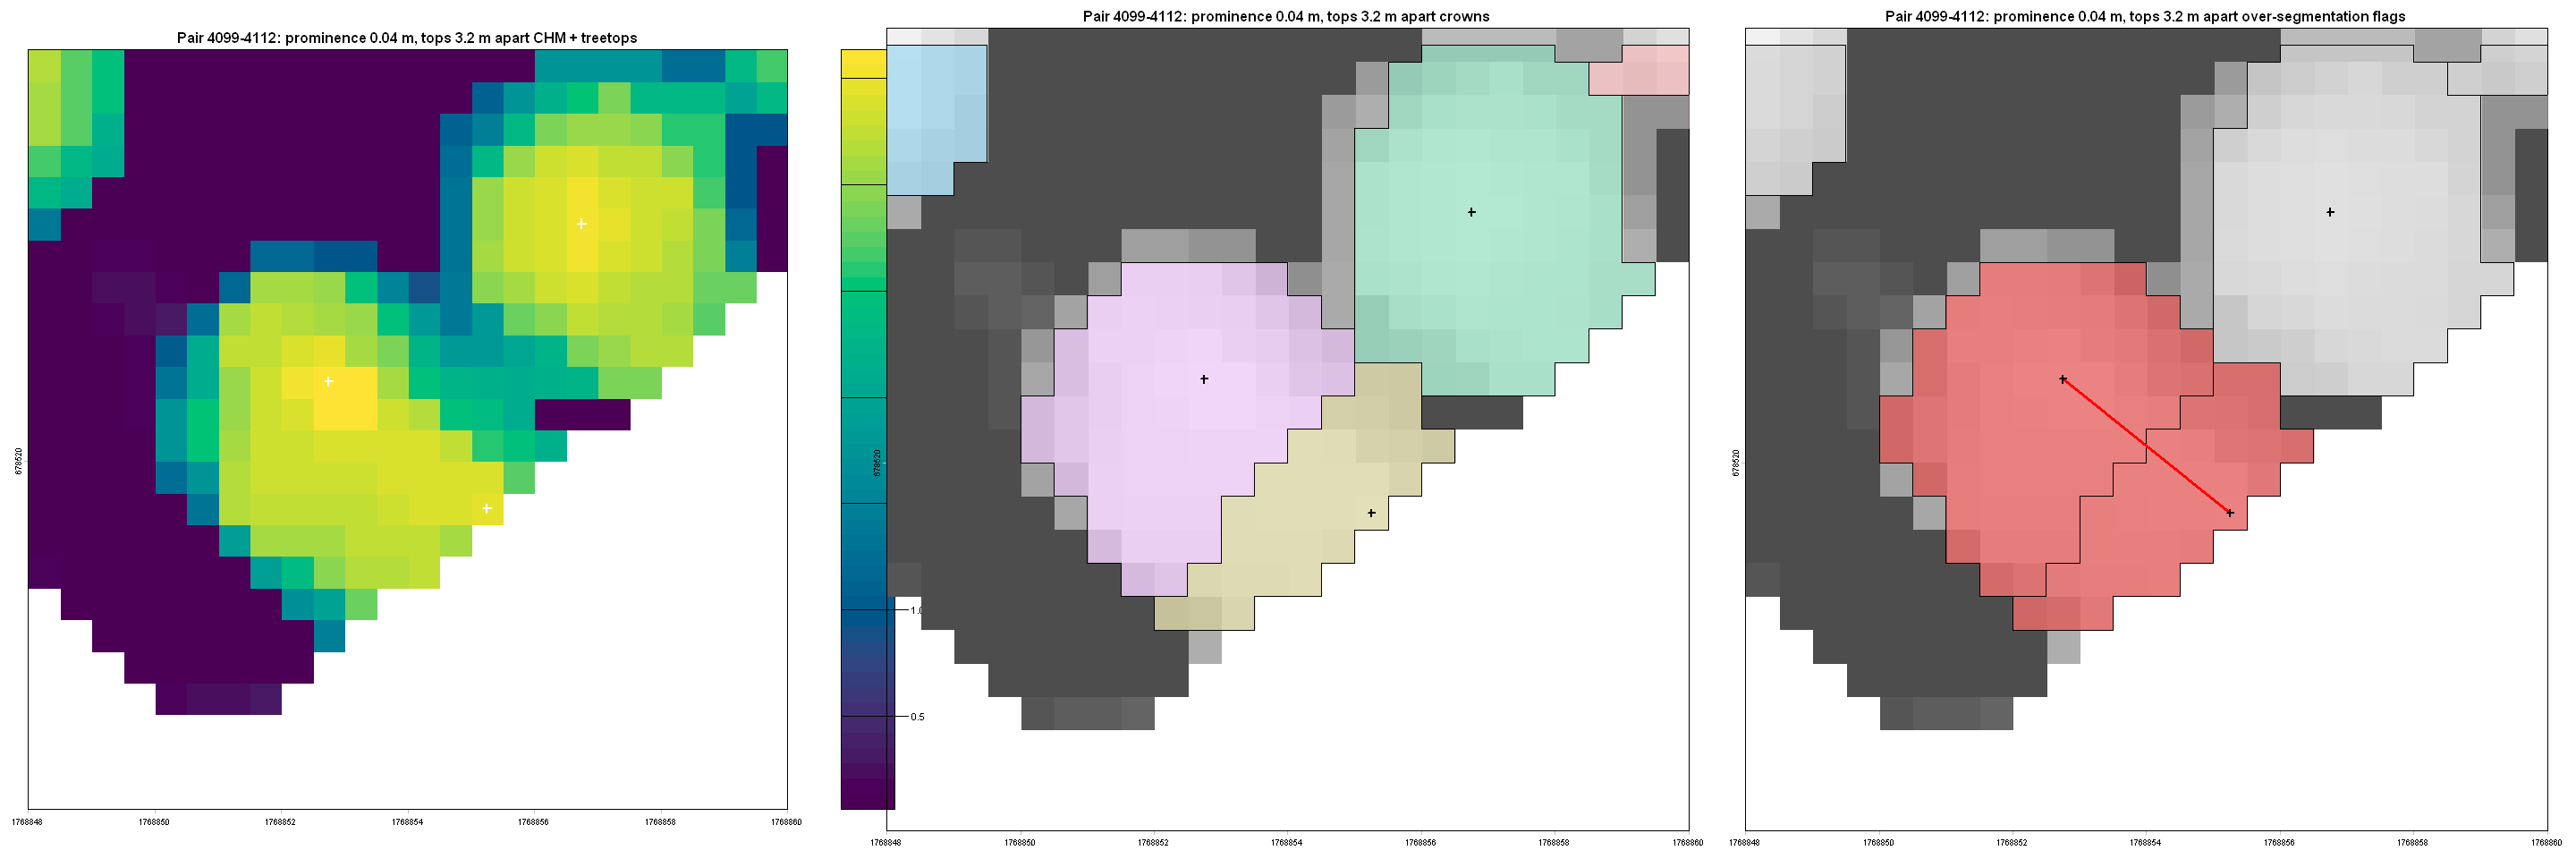

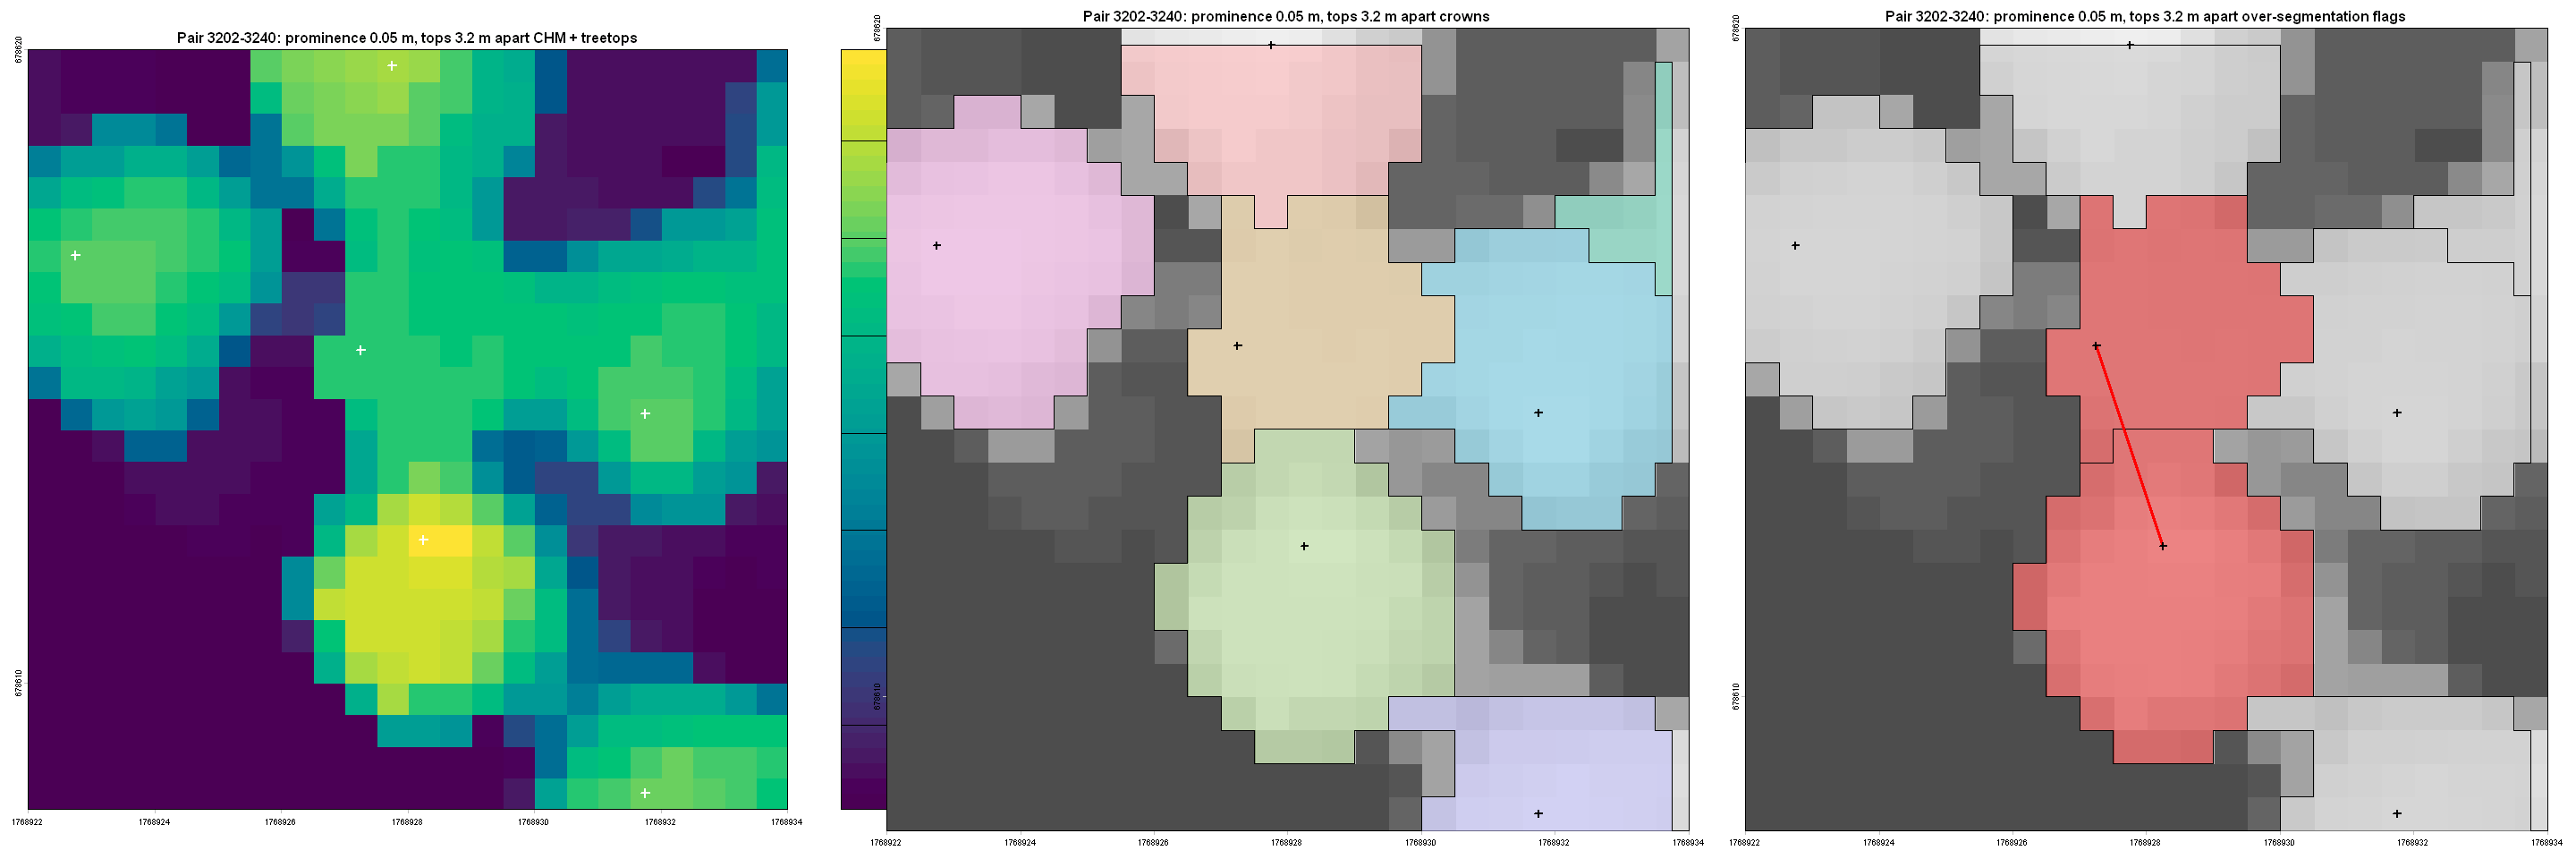

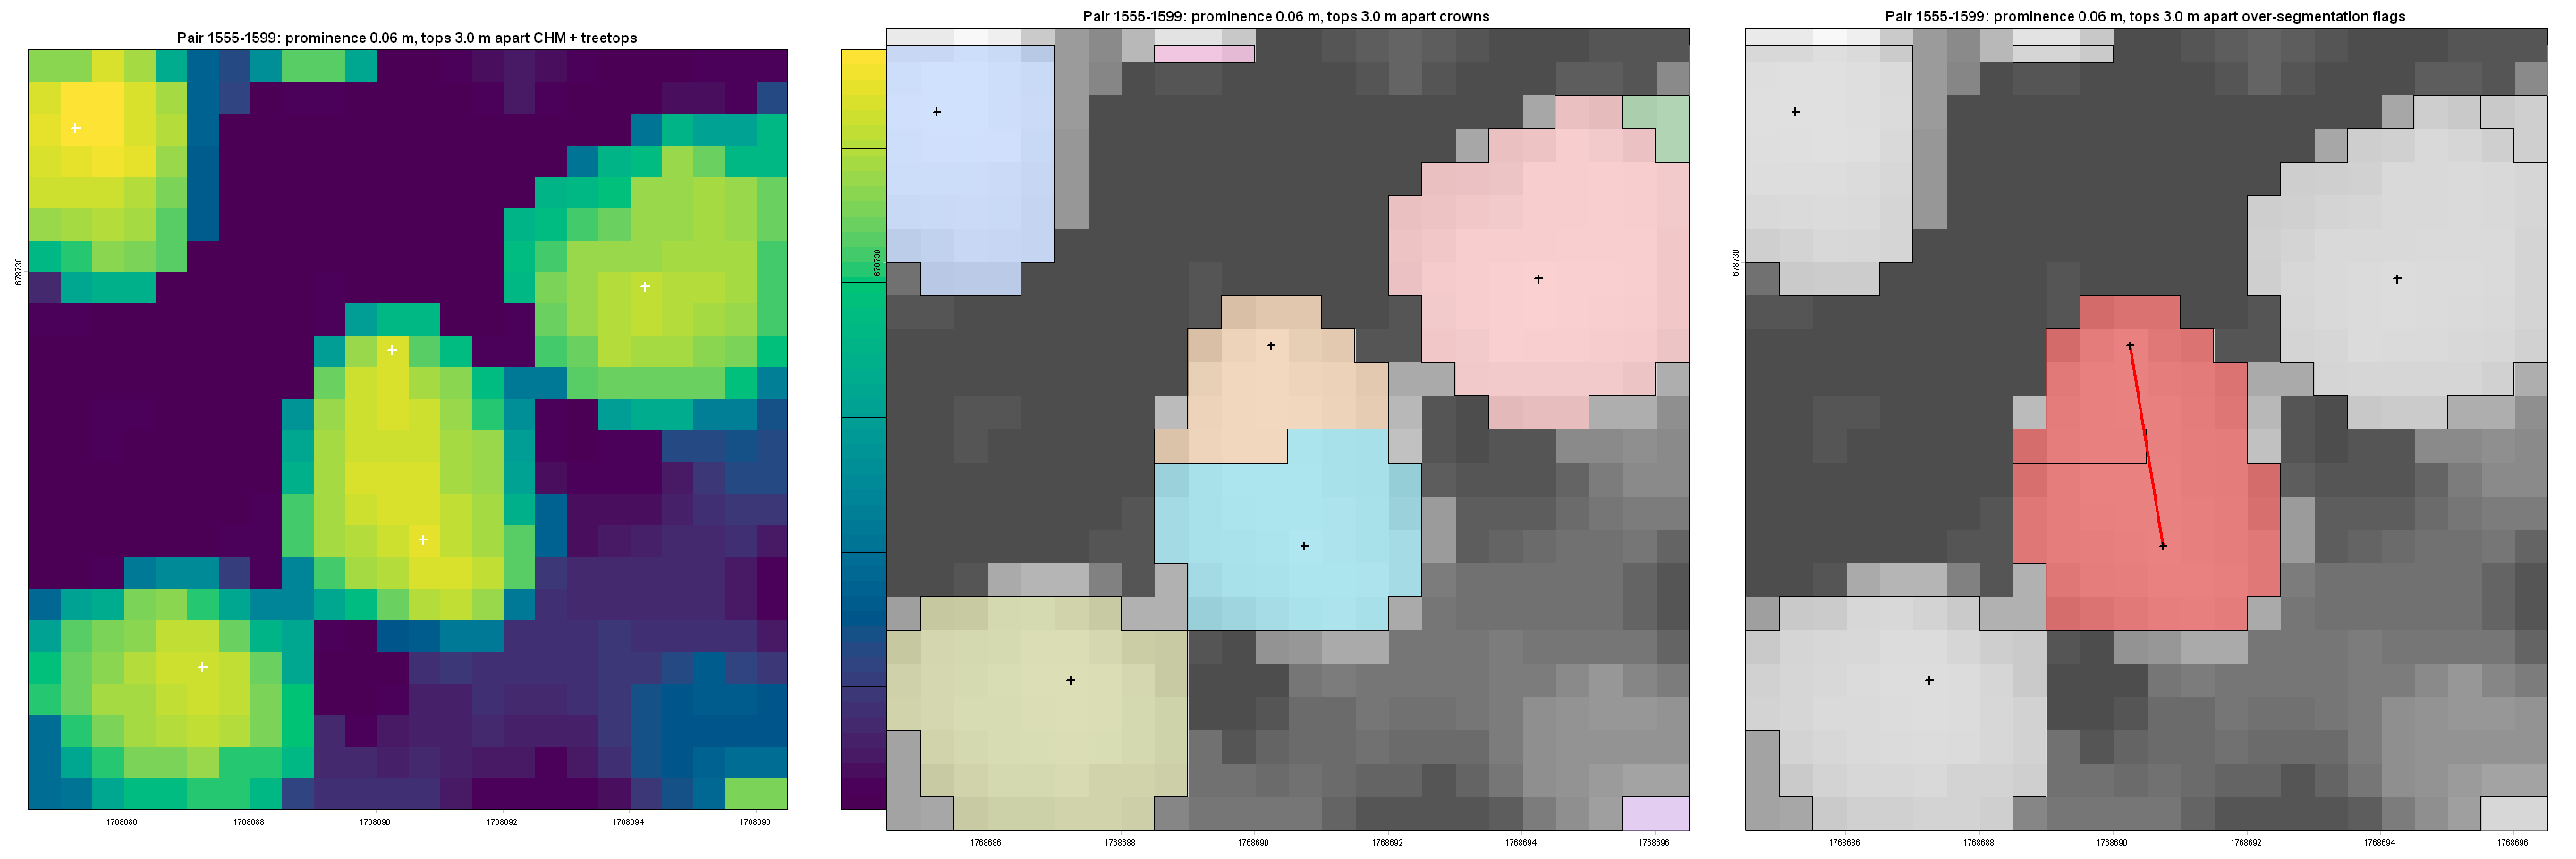

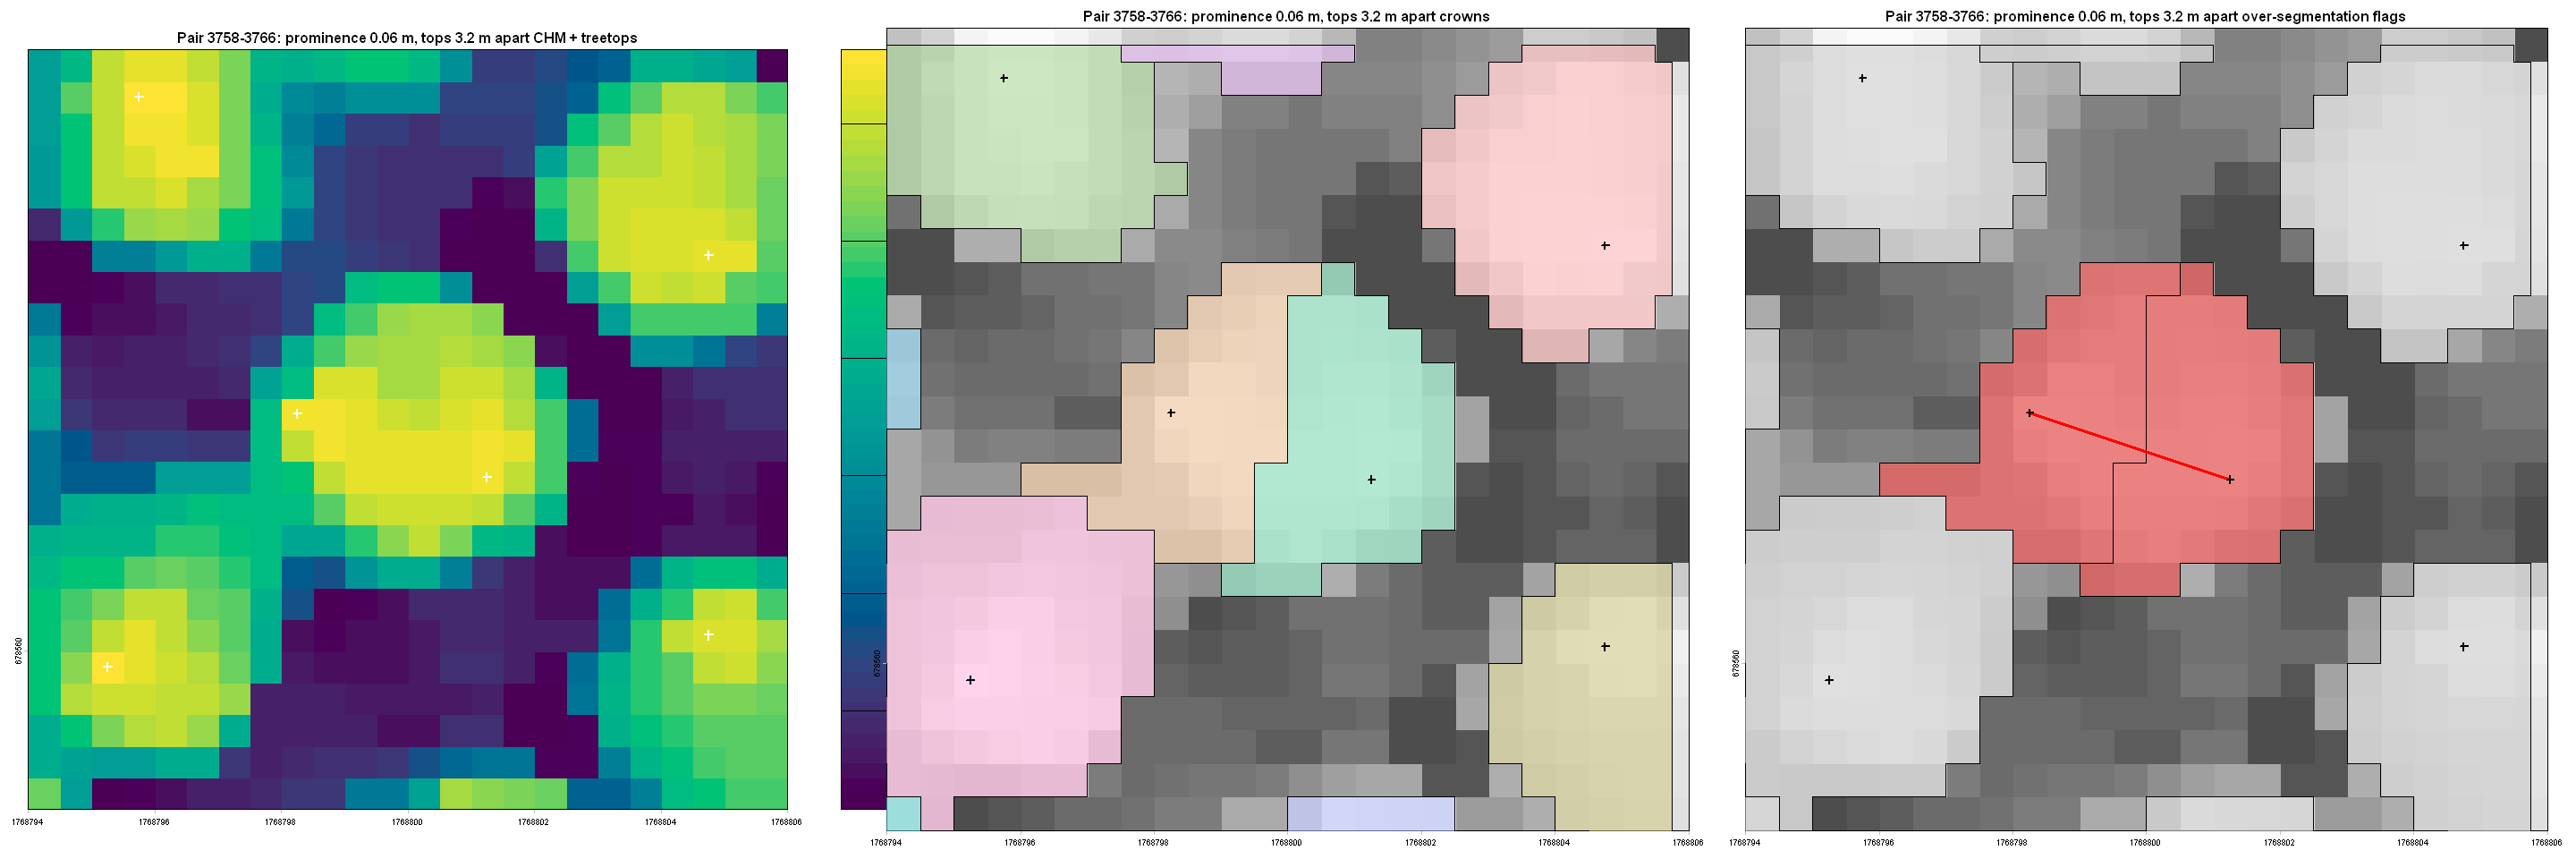

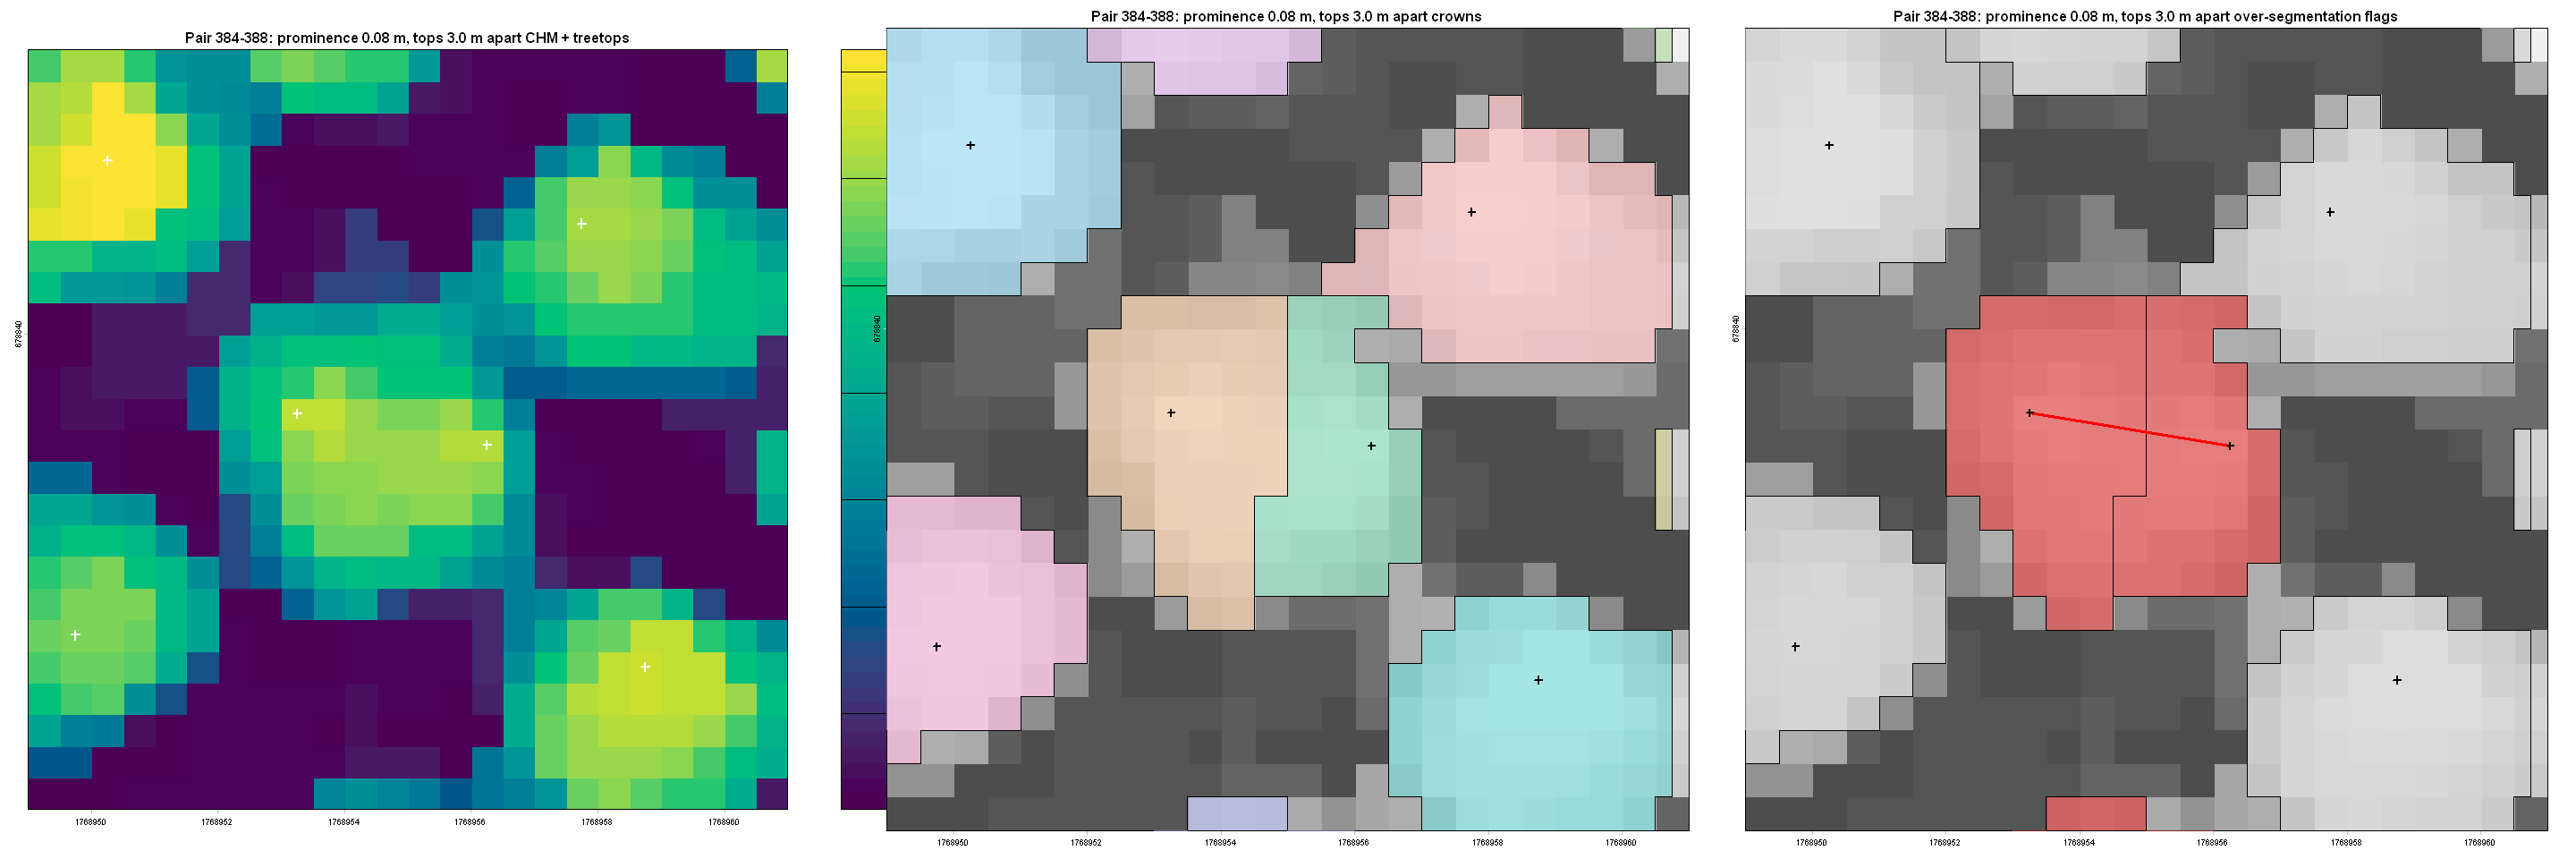

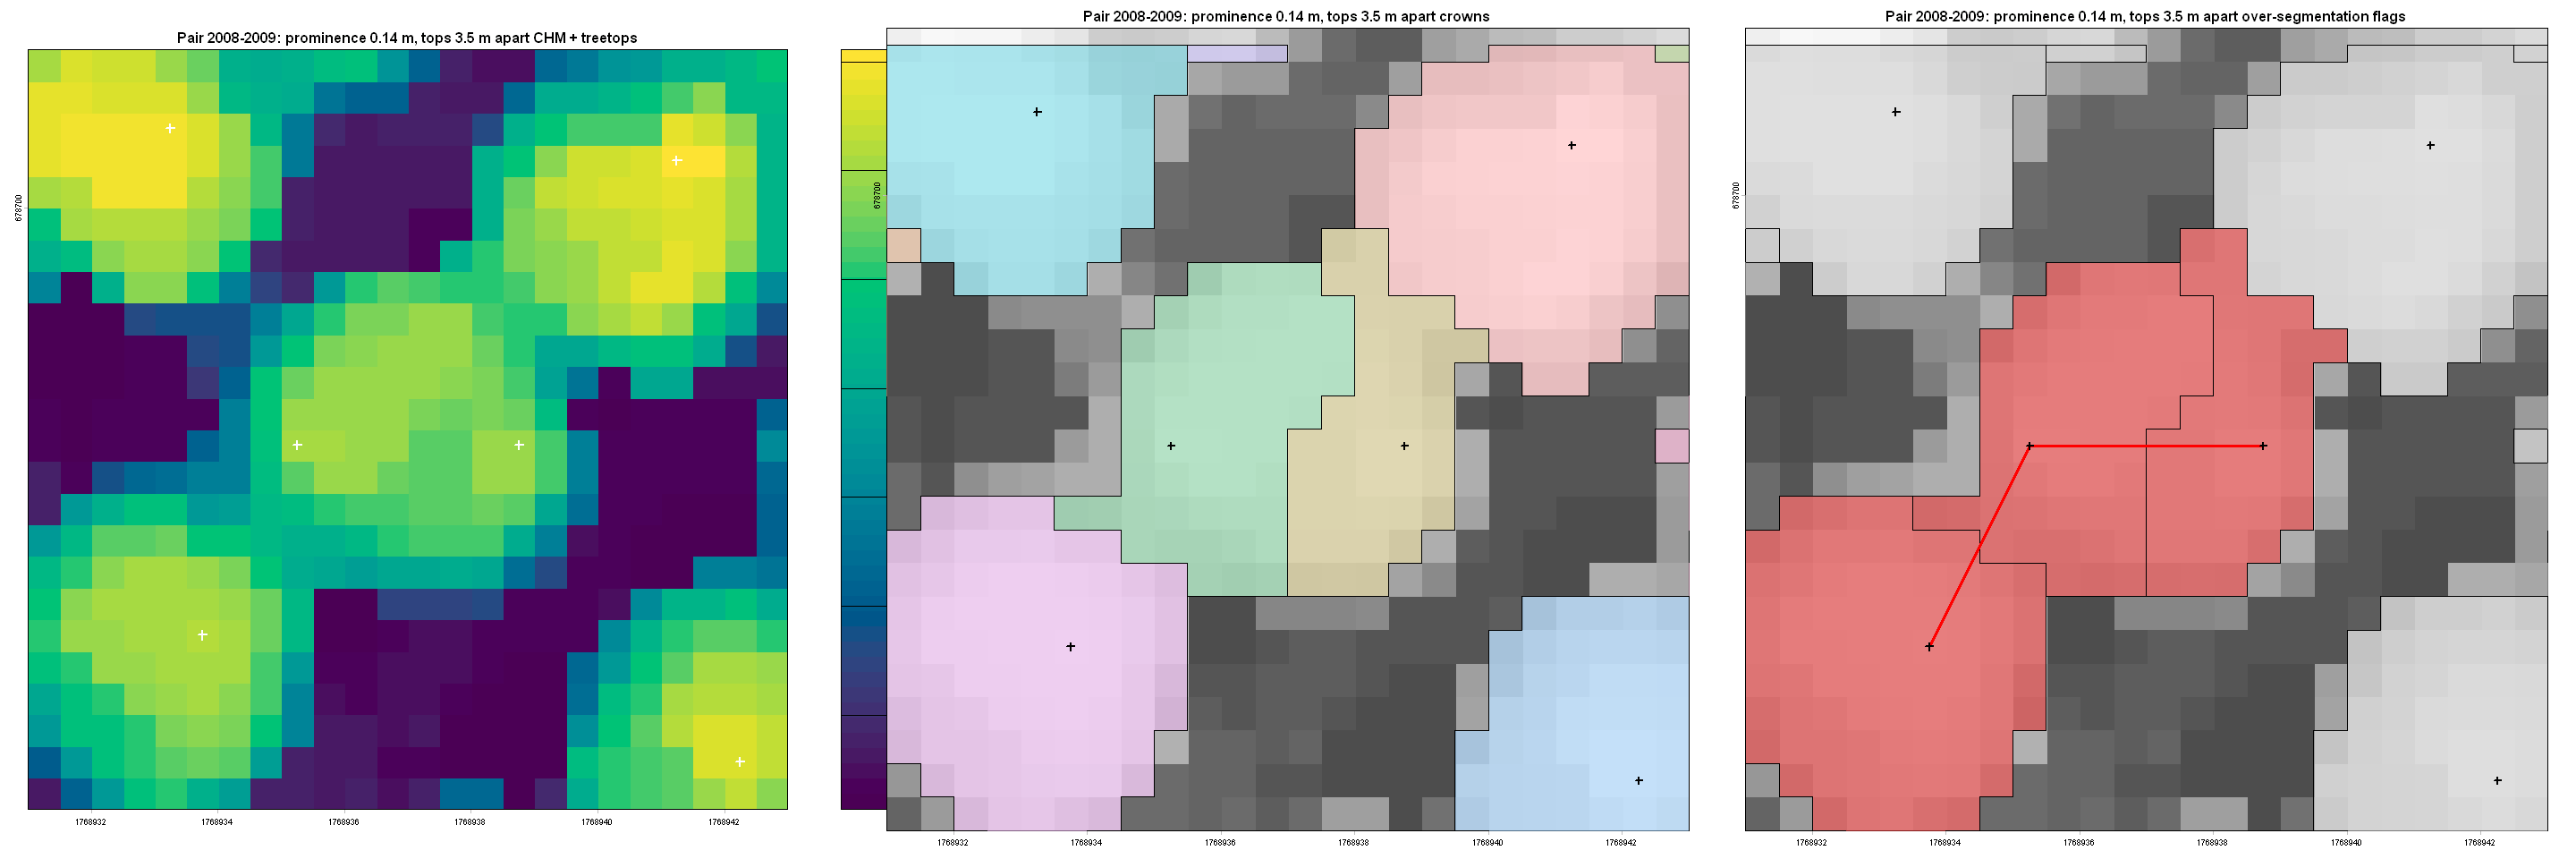

In [9]:
# The most likely over-segmentations in the whole scene (lowest prominence first)
worst <- suspect_pairs |> arrange(prominence) |> head(6)
for (k in seq_len(nrow(worst))) {
  xm <- (worst$xa[k] + worst$xb[k]) / 2; ym <- (worst$ya[k] + worst$yb[k]) / 2
  plot_overseg_window(chm_smooth, polys, ttops, suspect_pairs, ext(xm - 6, xm + 6, ym - 6, ym + 6),
                      title = sprintf("Pair %d-%d: prominence %.2f m, tops %.1f m apart",
                                      worst$a[k], worst$b[k], worst$prominence[k], worst$dist_m[k]))
}

## 7. Watershed vs Dalponte (same treetops)

Registered S3 method overwritten by 'stars':
  method                  from
  st_interpolate_aw.stars sf  



Median crown area  watershed: 17.8 m2 | Dalponte: 17.8 m2


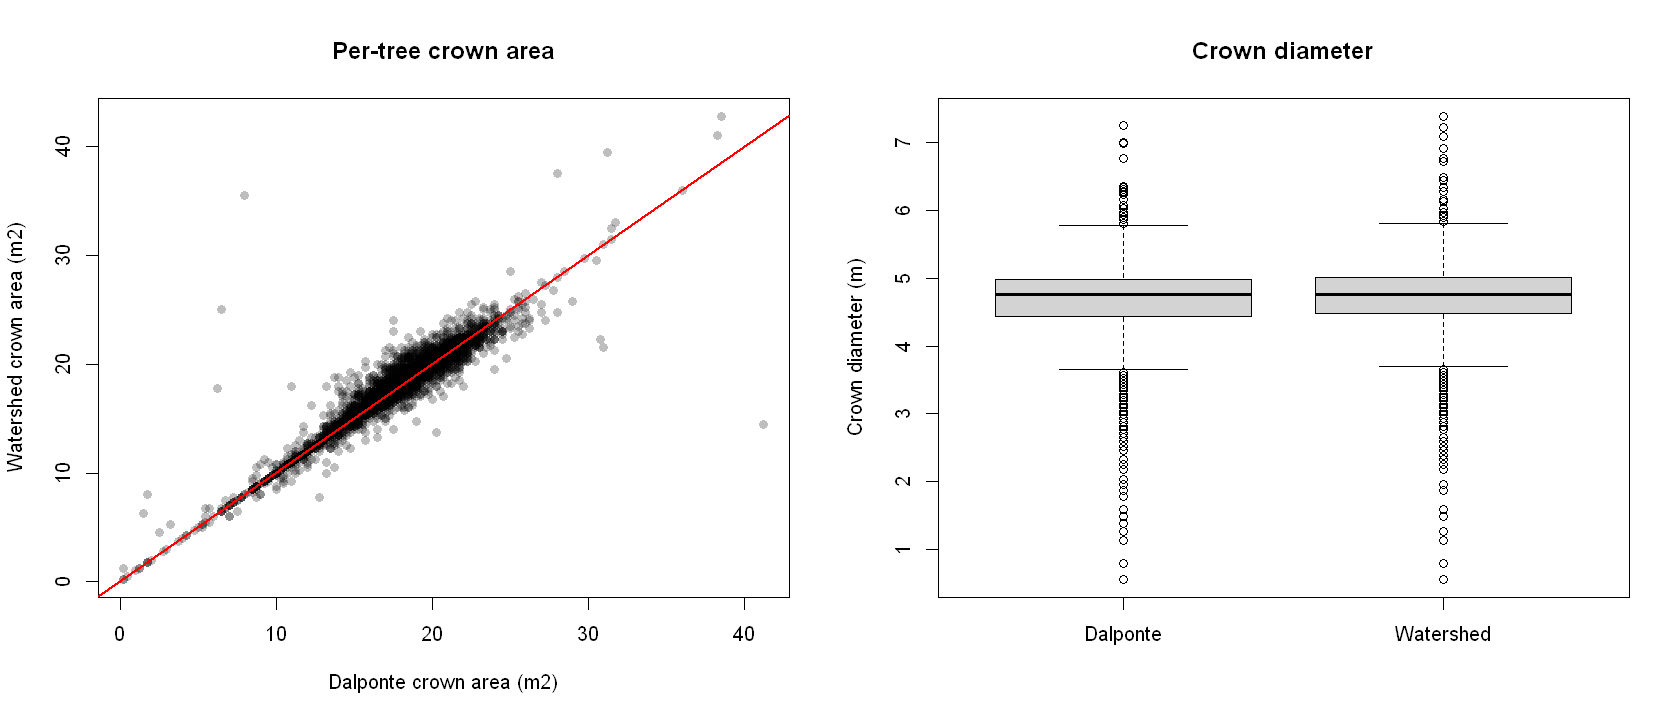

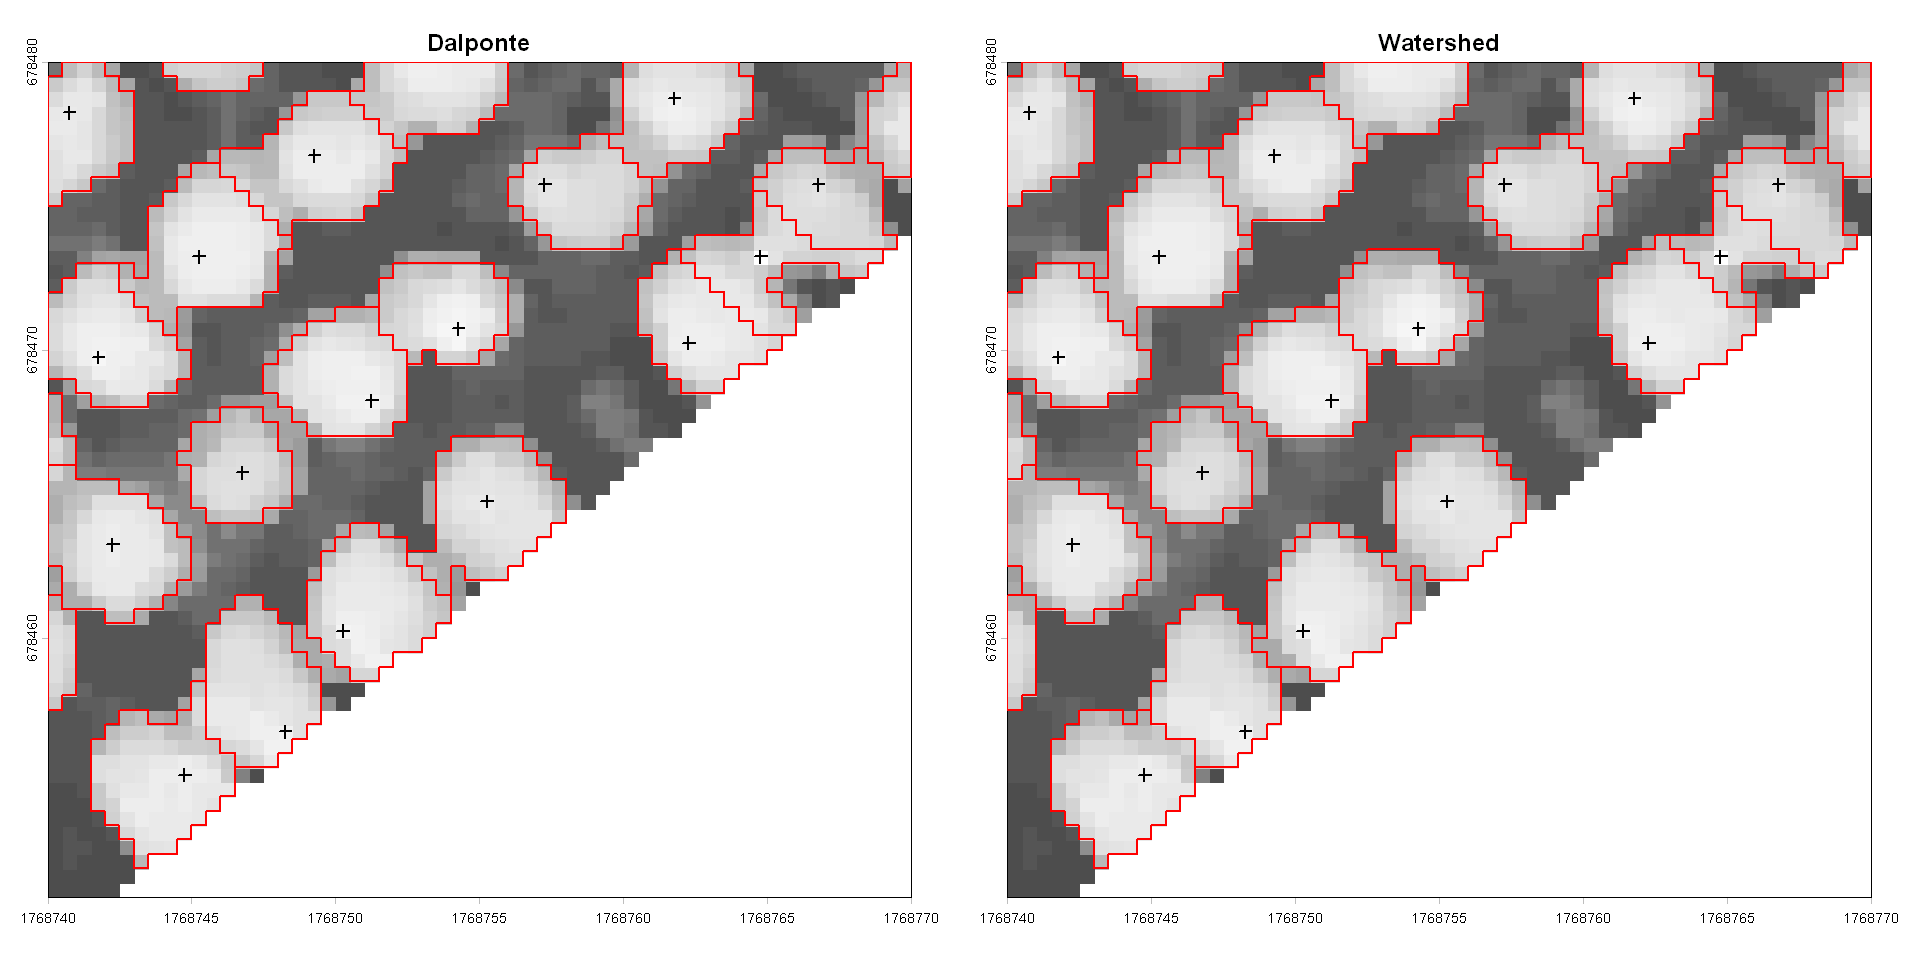

In [10]:
crowns_dal <- dalponte2016(chm_smooth, ttops, th_tree = cfg$th_tree, th_seed = cfg$th_seed,
                           th_cr = cfg$th_cr, max_cr = ceiling(cfg$max_cr_m / res_m))()
polys_dal <- crown_polygons(crowns_dal, chm_smooth, ttops)

cmp <- inner_join(
  st_drop_geometry(polys)     |> select(treeID, area_ws = area_m2),
  st_drop_geometry(polys_dal) |> select(treeID, area_dal = area_m2), by = "treeID")

cat(sprintf("Median crown area  watershed: %.1f m2 | Dalponte: %.1f m2\n", median(cmp$area_ws), median(cmp$area_dal)))

options(repr.plot.width = 14, repr.plot.height = 6)
par(mfrow = c(1, 2))
plot(cmp$area_dal, cmp$area_ws, pch = 16, col = adjustcolor("black", 0.25),
     xlab = "Dalponte crown area (m2)", ylab = "Watershed crown area (m2)", main = "Per-tree crown area")
abline(0, 1, col = "red", lwd = 2)
boxplot(list(Dalponte = polys_dal$diam_m, Watershed = polys$diam_m), ylab = "Crown diameter (m)", main = "Crown diameter")
par(mfrow = c(1, 1))

# Side-by-side on the most over-segmented block
w  <- ext(blk$bx[1] * 30, (blk$bx[1] + 1) * 30, blk$by[1] * 30, (blk$by[1] + 1) * 30)   # most over-segmented block
bb <- st_bbox(c(xmin = xmin(w), xmax = xmax(w), ymin = ymin(w), ymax = ymax(w)), crs = st_crs(ttops))
options(repr.plot.width = 16, repr.plot.height = 8)
par(mfrow = c(1, 2))
for (nm in c("Dalponte", "Watershed")) {
  p <- if (nm == "Dalponte") polys_dal else polys
  plot(crop(chm_smooth, w), col = gray.colors(50, 0.3, 1), legend = FALSE, main = nm)
  plot(st_geometry(suppressWarnings(st_crop(p, bb))), border = "red", lwd = 2, add = TRUE, col = NA)
  plot(st_geometry(ttops[st_intersects(ttops, st_as_sfc(bb), sparse = FALSE)[, 1], ]), add = TRUE, pch = 3, lwd = 2)
}
par(mfrow = c(1, 1))

## 8. Compare to ground-measured heights

Same matching as the Dalponte notebook (heights come from the shared treetops, so only the raw-CHM-max column depends on the crowns).

In [11]:
ground  <- read_ground_trees(ground_path, st_crs(chm))
matched <- match_ground_trees(ground, ttops, polys, chm, cfg$match_max_dist)

cat(sprintf("\nMatched %d of %d surveyed trees within %.1f m (median distance %.2f m)\n",
            nrow(matched), nrow(ground), cfg$match_max_dist, median(matched$dist_m)))

metrics <- rbind(`smoothed treetop height` = height_metrics(matched$seg_height_m, matched$gt_height_m),
                 `raw CHM max in crown`    = height_metrics(matched$raw_max_m,    matched$gt_height_m))
cat("All matches:\n"); print(round(metrics, 3))

# Same, dropping gross mismatches (likely a wrong match or a bad field height, not segmentation error)
ok <- abs(matched$err_seg) < cfg$outlier_m
cat(sprintf("\nExcluding %d match(es) with |error| >= %.0f m:\n", sum(!ok), cfg$outlier_m))
print(round(rbind(`smoothed treetop height` = height_metrics(matched$seg_height_m[ok], matched$gt_height_m[ok]),
                  `raw CHM max in crown`    = height_metrics(matched$raw_max_m[ok],    matched$gt_height_m[ok])), 3))
cat("\nNote: R2 is weak evidence here - surveyed heights span only ~1.4-3.9 m.\n")

ground_tbl <- data.frame(
  ground_row = seq_len(nrow(ground)),
  label      = ground$Tree_Label,
  gt_x       = st_coordinates(ground)[, 1],
  gt_y       = st_coordinates(ground)[, 2],
  gt_height_m = ground$gt_height_m,
  gt_dbh      = ground$GT_DBH
)

comparison <- ground_tbl |>
  left_join(
    matched |> select(ground_row, seg_treeID = treeID, seg_x = xt, seg_y = yt, dist_m,
                      seg_height_m, raw_max_m, err_seg, err_raw),
                      # err_raw = the highest raw CHM value anywhere inside the whole crown polygon, which came from the smoothed segmentation
                      # err_seg = the segmented chm height minus the ground height, using the smoothed treetop height
    by = "ground_row"
  ) |>
    left_join(
    st_drop_geometry(polys) |> select(seg_treeID = treeID, crown_diam_m = diam_m, crown_area_m2 = area_m2),
    by = "seg_treeID"
  ) |>
  mutate(
    matched    = !is.na(seg_treeID),
    pct_err    = round(100 * err_seg / gt_height_m, 1),
    gross_miss = abs(err_seg) >= cfg$outlier_m
  ) |>
    mutate(
    gt_biomass    = 53.03 - 6.64 * gt_dbh + 0.53 * gt_dbh^2 - 0.01 * gt_dbh^3,
    drone_biomass = -1.64 + 6.73 * crown_diam_m + 2.87 * raw_max_m^2,
    biomass_diff  = drone_biomass - gt_biomass,
    biomass_pct   = round(100 * biomass_diff / gt_biomass, 1)
  ) |>
  select(label, gt_dbh, gt_height_m, seg_height_m, err_raw, gt_biomass, drone_biomass, biomass_diff, biomass_pct, crown_diam_m, crown_area_m2, gt_x, gt_y, seg_treeID, seg_x, seg_y, dist_m,
         err_seg, pct_err, raw_max_m, matched, gross_miss) |>
arrange(
    suppressWarnings(as.numeric(sub("\\..*", "", label))),   # part before the dot (e.g. 1, 2, 10)
    suppressWarnings(as.numeric(sub(".*\\.", "", label))),   # part after the dot
    label                                                    # non-numeric labels (e.g. "Phytech") last, alphabetical
  )


print(comparison, digits = 3)   # or View(comparison)
write.csv(comparison, file.path(out_dir, "ground_height_comparison.csv"), row.names = FALSE)


Matched 120 of 120 surveyed trees within 4.0 m (median distance 2.08 m)
All matches:
                          n  bias   MAE  RMSE    R2
smoothed treetop height 120 0.336 0.344 0.391 0.767
raw CHM max in crown    120 0.498 0.499 0.550 0.714

Excluding 0 match(es) with |error| >= 5 m:
                          n  bias   MAE  RMSE    R2
smoothed treetop height 120 0.336 0.344 0.391 0.767
raw CHM max in crown    120 0.498 0.499 0.550 0.714

Note: R2 is weak evidence here - surveyed heights span only ~1.4-3.9 m.
    label gt_dbh gt_height_m seg_height_m err_raw gt_biomass drone_biomass
1     3.1   17.3         2.4         2.67   0.501       45.0          56.0
2     3.2   17.6         2.6         2.99   0.569       45.8          60.7
3     3.3   17.4         2.8         3.22   0.506       45.3          59.1
4     3.4   18.2         2.6         3.04   0.494       47.5          56.4
5     3.5   17.0         2.6         2.83   0.321       44.2          53.2
6     3.6   17.6         2.5       

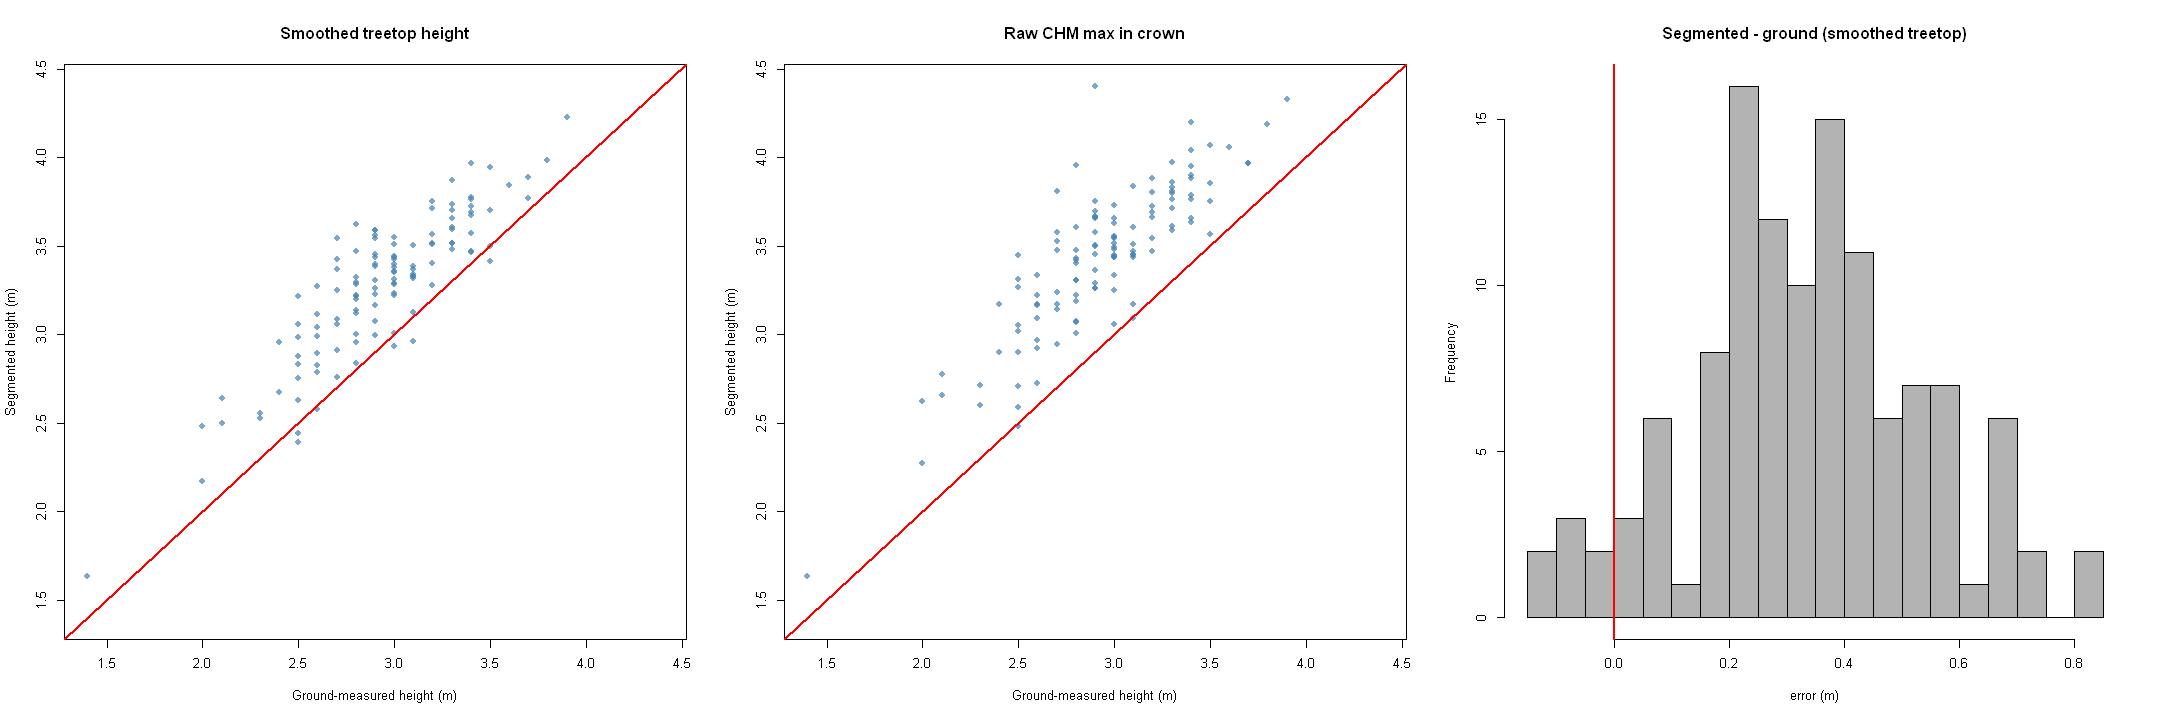

,label,dist_m,gt_height_m,seg_height_m,raw_max_m,err_seg
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,9.16,3.1078889,2.7,3.543003,3.807004,0.8430033
2,3.14,0.7057493,2.8,3.624999,3.956000,0.8249988
3,10.12,0.5147193,2.7,3.422998,3.575002,0.7229980
4,4.11,1.9386451,2.5,3.216001,3.447996,0.7160006
5,4.13,2.5684795,2.9,3.589998,3.750000,0.6899975
6,9.9,3.2093720,2.9,3.587002,3.668998,0.6870020
7,4.6,1.3679316,2.6,3.272001,3.331999,0.6720013
8,6.3,1.5046634,2.7,3.370997,3.525003,0.6709967
9,3.13,3.1728074,2.8,3.469998,3.604996,0.6699976


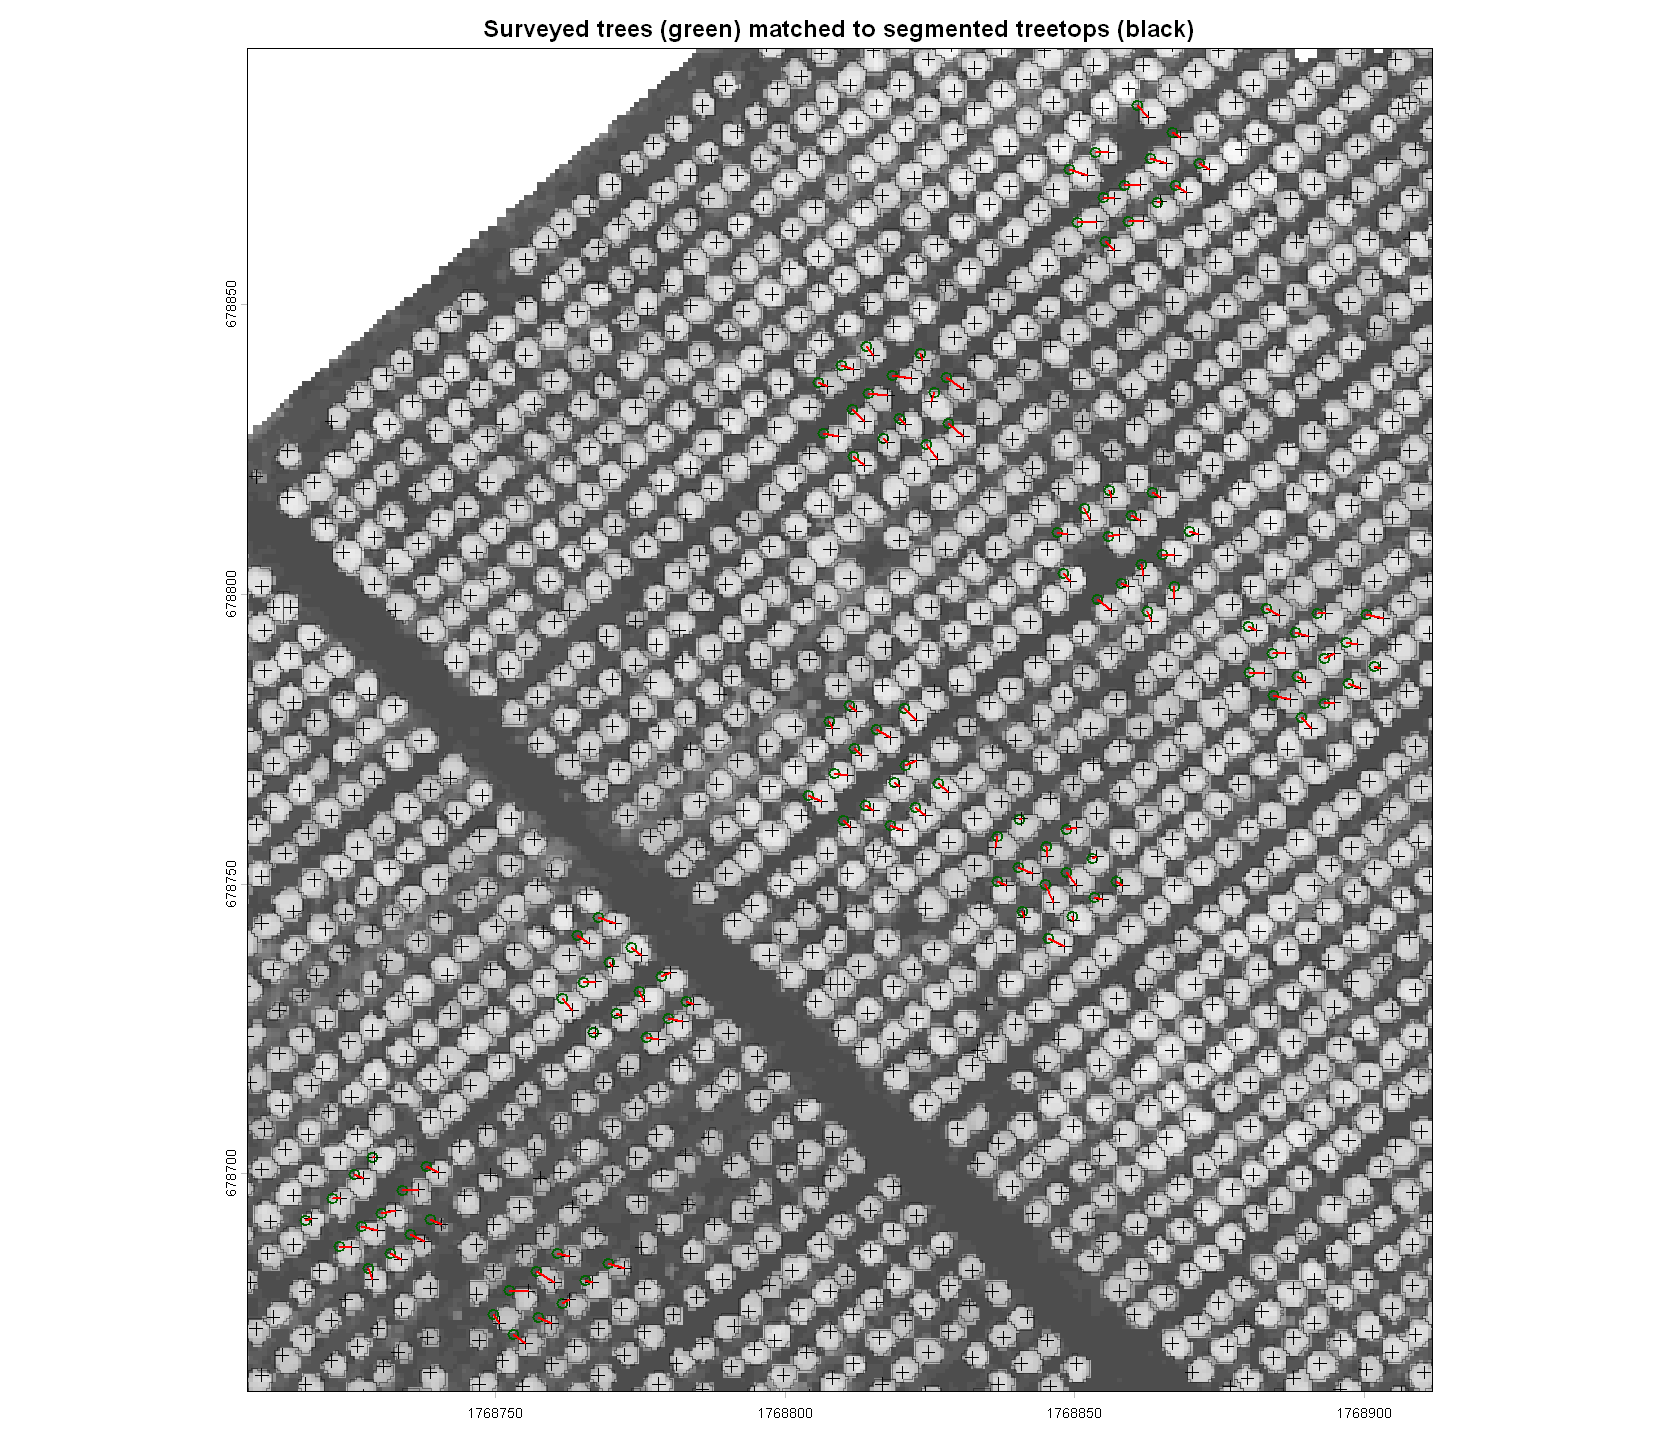

In [12]:
options(repr.plot.width = 18, repr.plot.height = 6)
par(mfrow = c(1, 3))
lim <- range(c(matched$gt_height_m, matched$seg_height_m, matched$raw_max_m), na.rm = TRUE)
for (v in c("seg_height_m", "raw_max_m")) {
  plot(matched$gt_height_m, matched[[v]], xlim = lim, ylim = lim, pch = 16, col = adjustcolor("steelblue", 0.7),
       xlab = "Ground-measured height (m)", ylab = "Segmented height (m)",
       main = if (v == "seg_height_m") "Smoothed treetop height" else "Raw CHM max in crown")
  abline(0, 1, col = "red", lwd = 2)
}
hist(matched$err_seg, breaks = 20, col = "grey70", main = "Segmented - ground (smoothed treetop)", xlab = "error (m)")
abline(v = 0, col = "red", lwd = 2)
par(mfrow = c(1, 1))

# Where the matches are: surveyed tree -> segmented treetop link on the CHM
options(repr.plot.width = 14, repr.plot.height = 12)
plot(chm_smooth, col = gray.colors(50, 0.3, 1), legend = FALSE, main = "Surveyed trees (green) matched to segmented treetops (black)",
     ext = ext(vect(st_buffer(st_as_sfc(st_bbox(ground)), 10))))
plot(st_geometry(polys), border = adjustcolor("black", 0.4), col = NA, add = TRUE)
plot(st_geometry(ground), add = TRUE, pch = 1, col = "darkgreen", cex = 1.2, lwd = 2)
plot(st_geometry(ttops), add = TRUE, pch = 3, col = "black")
segments(matched$xg, matched$yg, matched$xt, matched$yt, col = "red", lwd = 2)

# Largest height errors
matched |> arrange(desc(abs(err_seg))) |> select(label, dist_m, gt_height_m, seg_height_m, raw_max_m, err_seg) |> head(10)

# Print images of all of the matched Drone Height locations to Arrow Coordinates of Trees
this could potenitally get updated to just show the ones that did not get matched? with over 200 trees this is super long and not really needed unless troubleshooting what the proper distance looking for matching should be

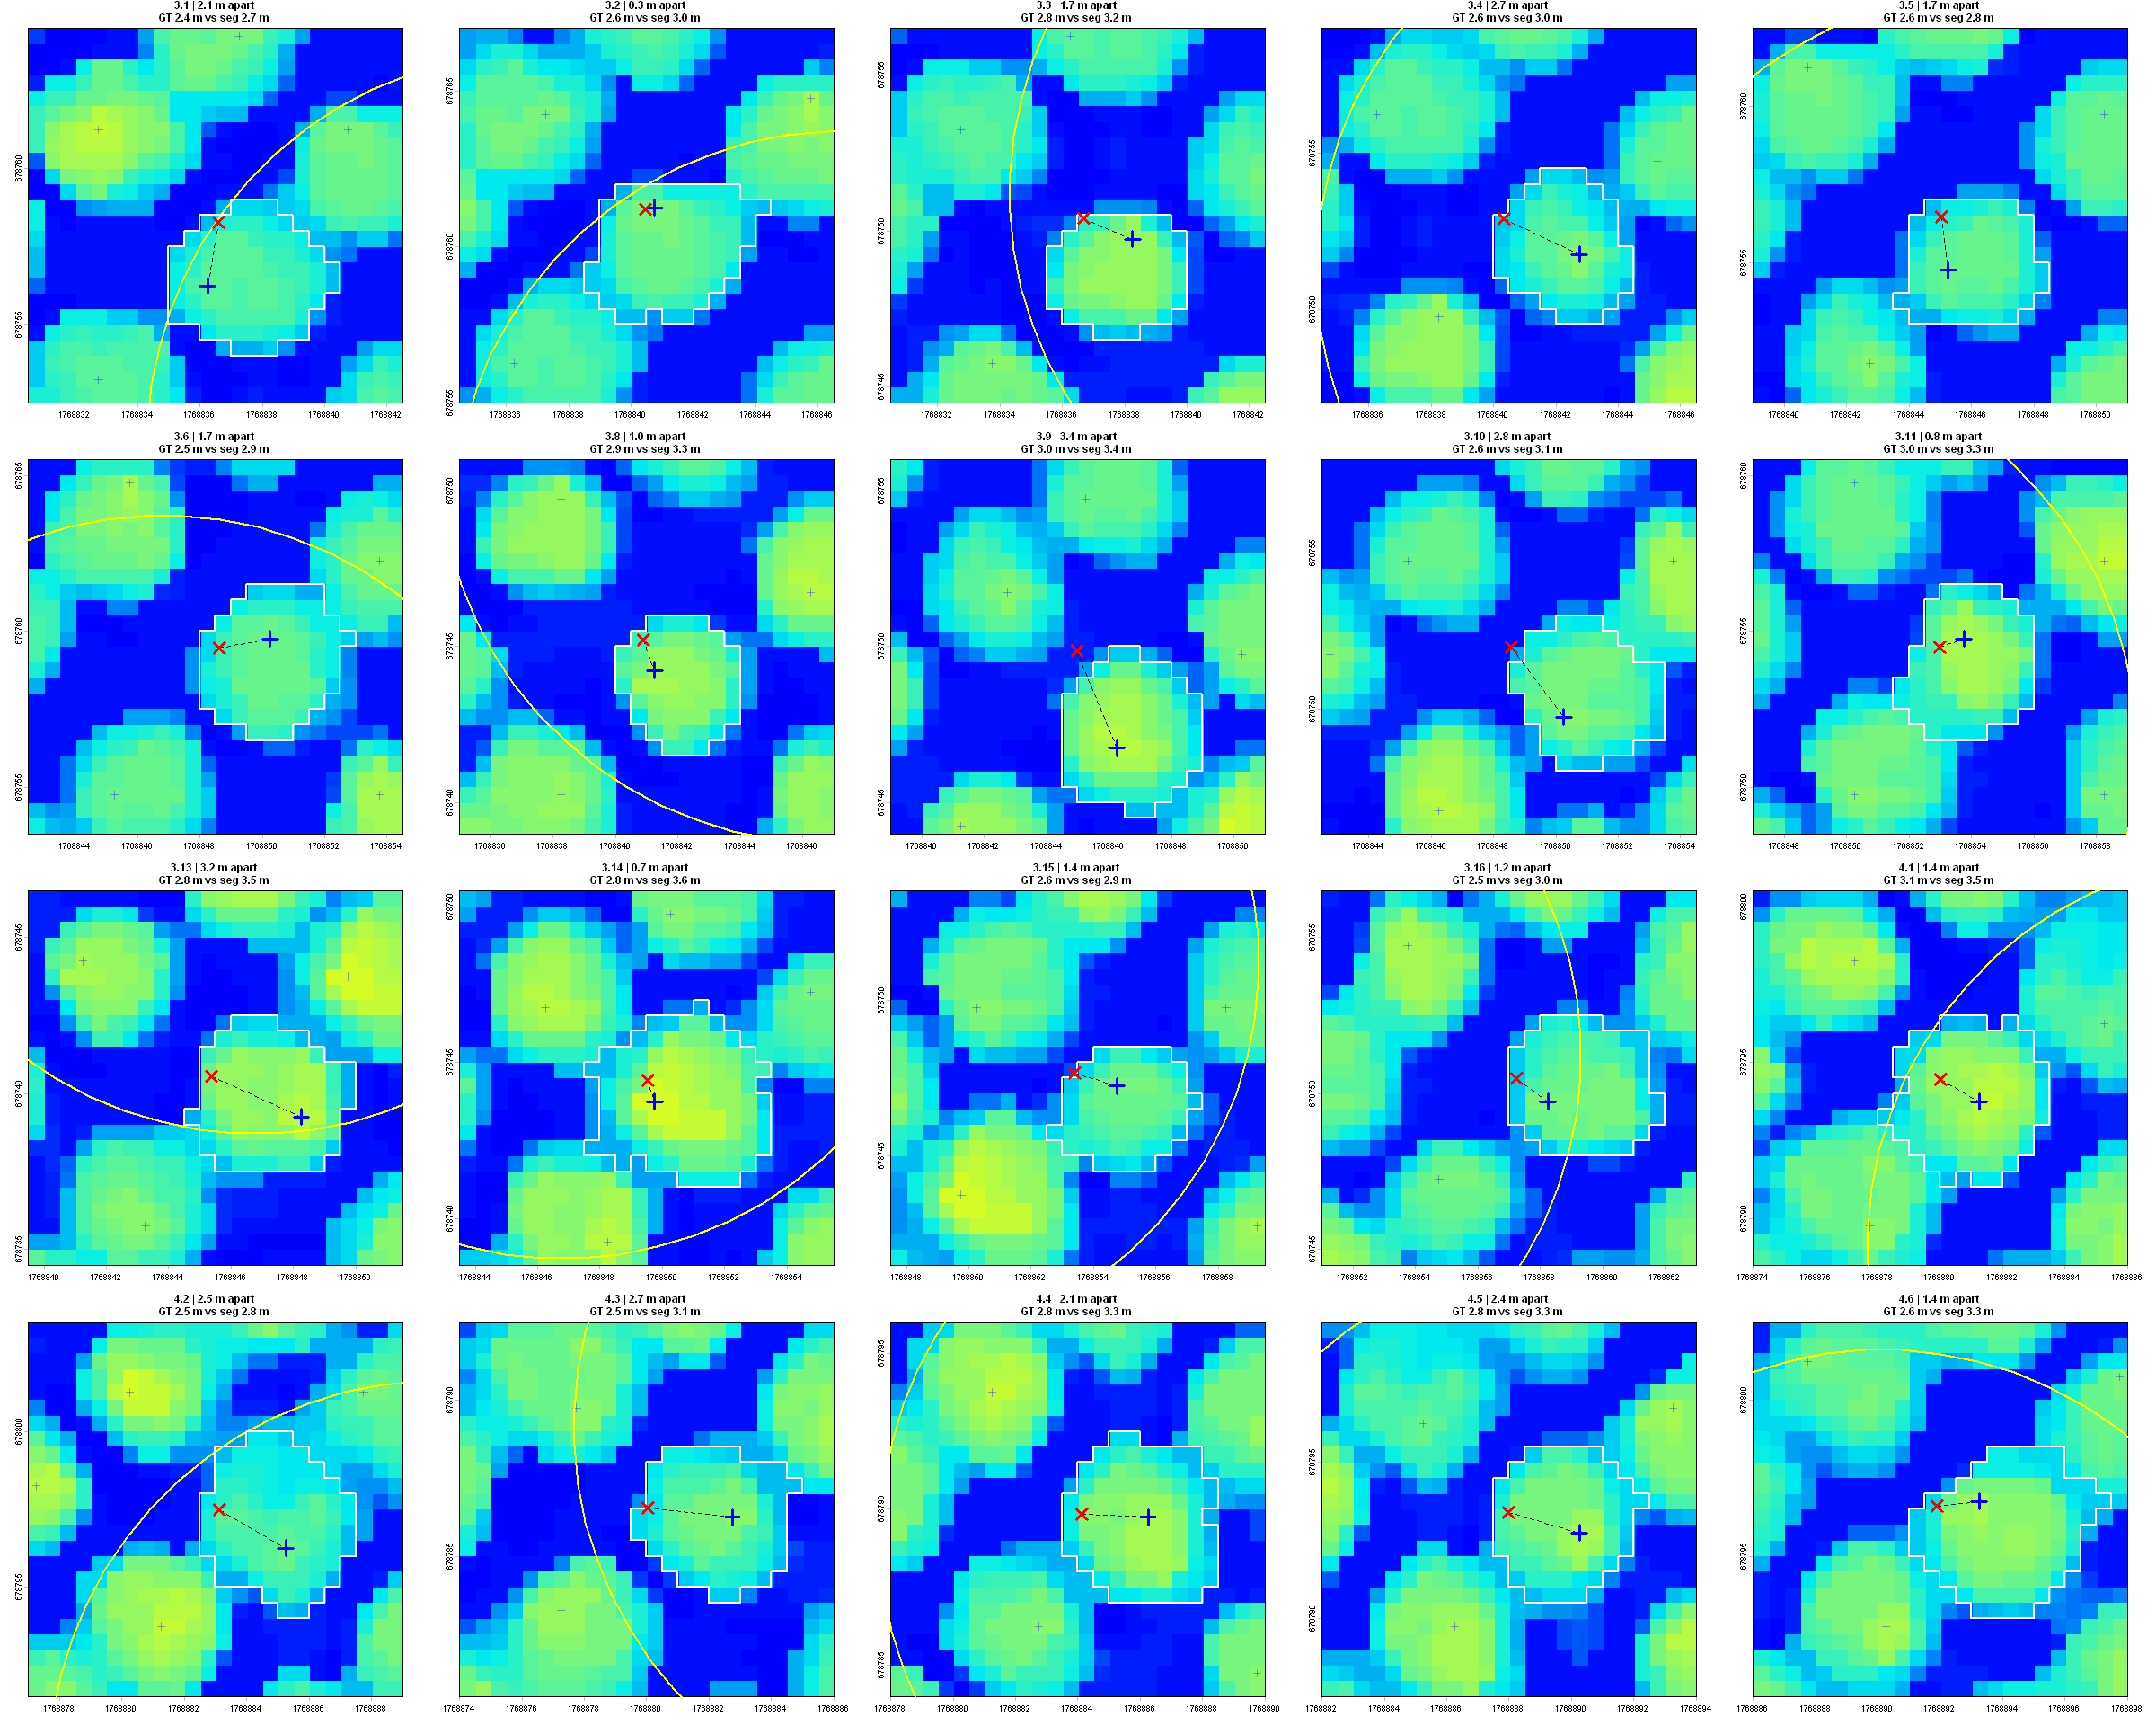

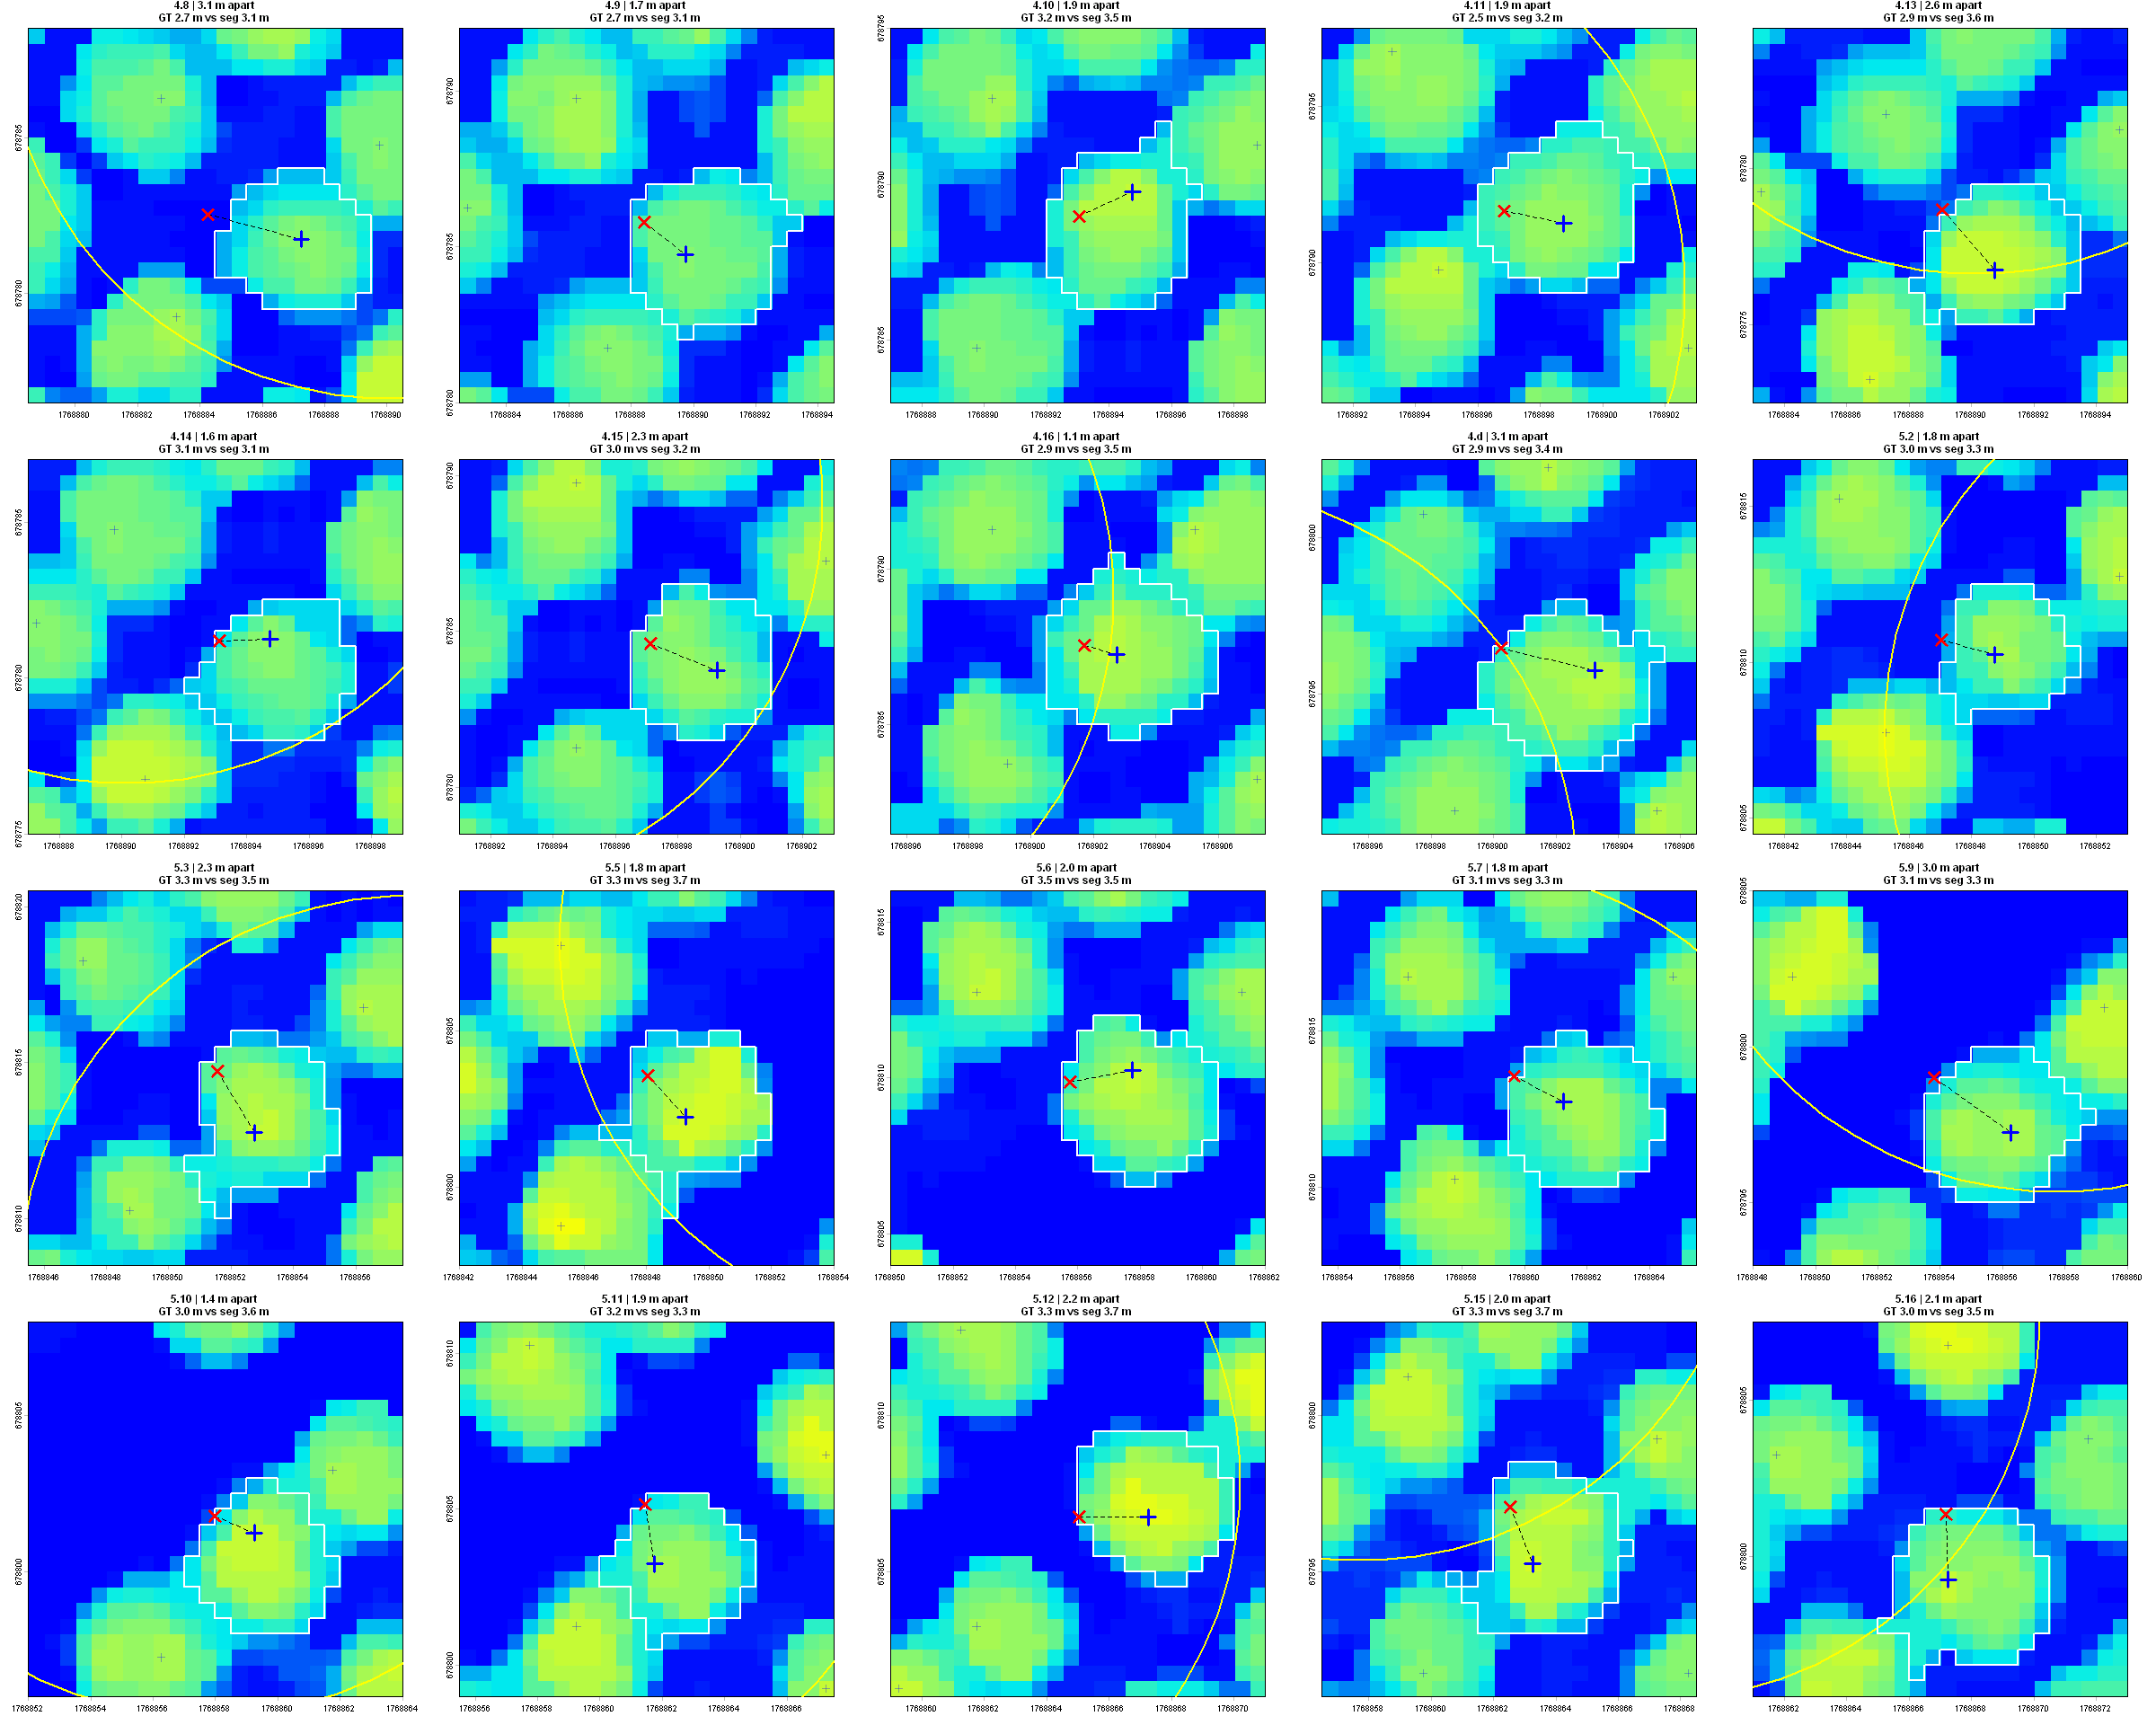

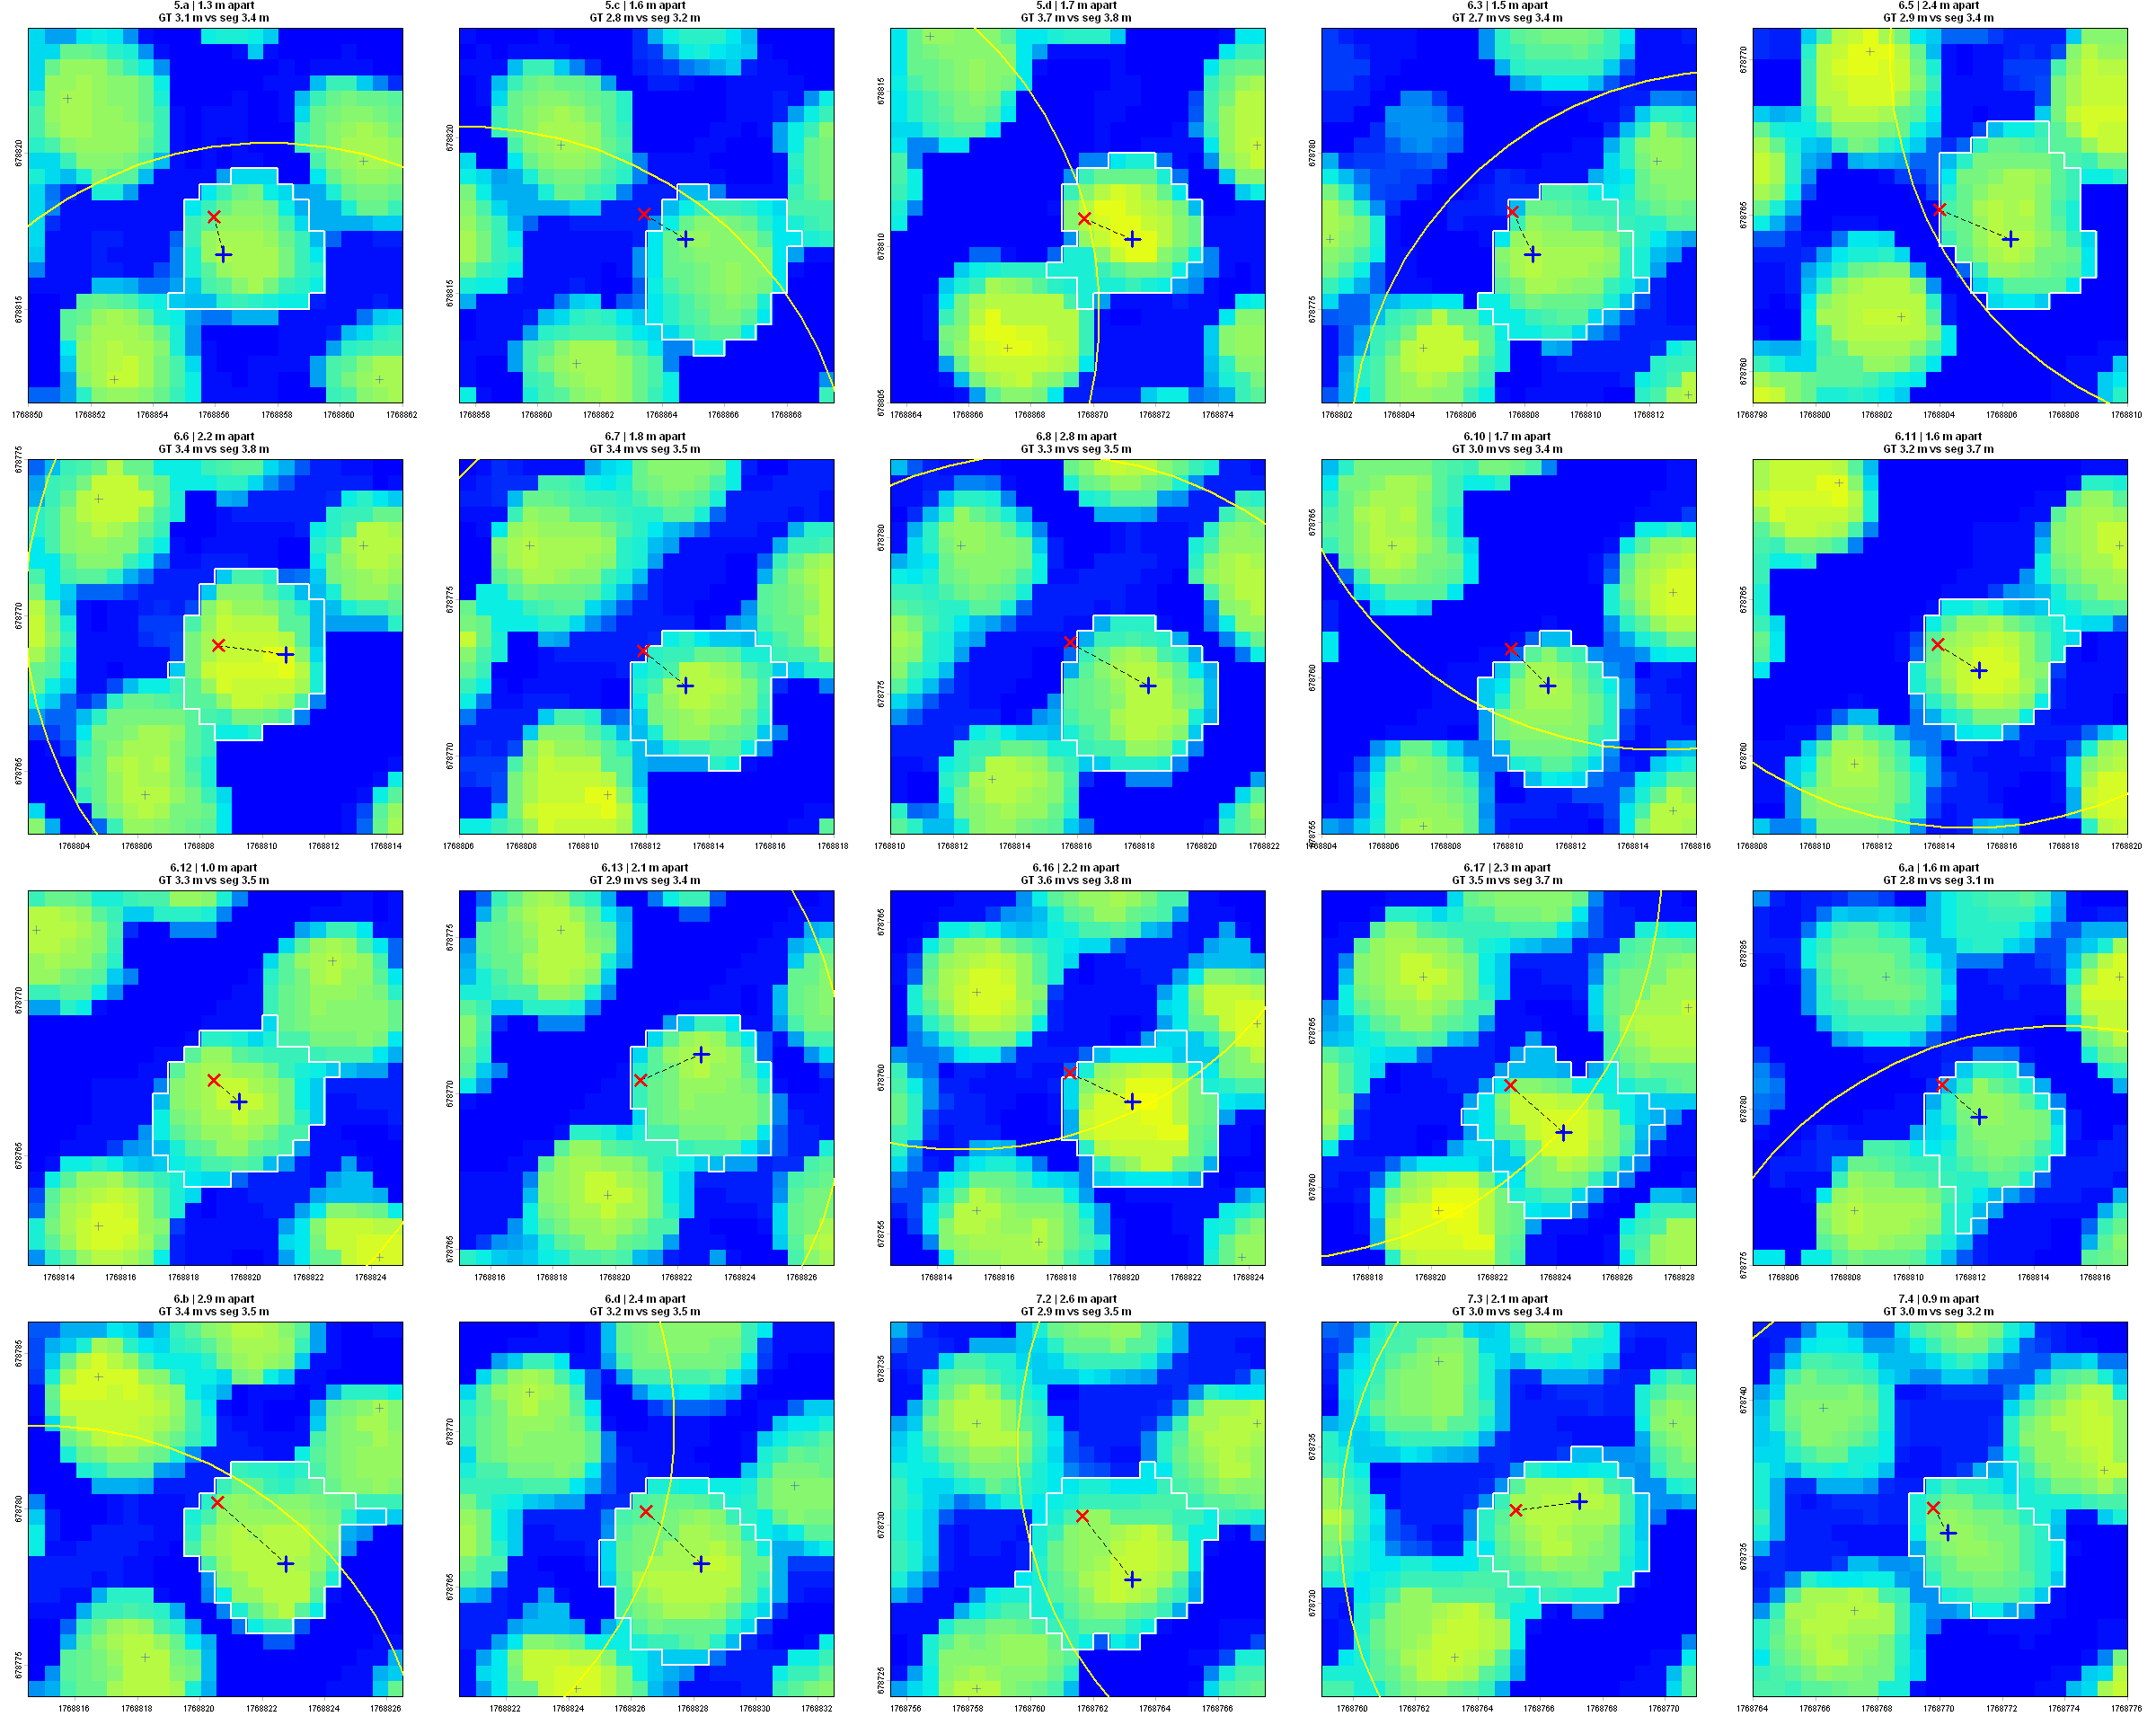

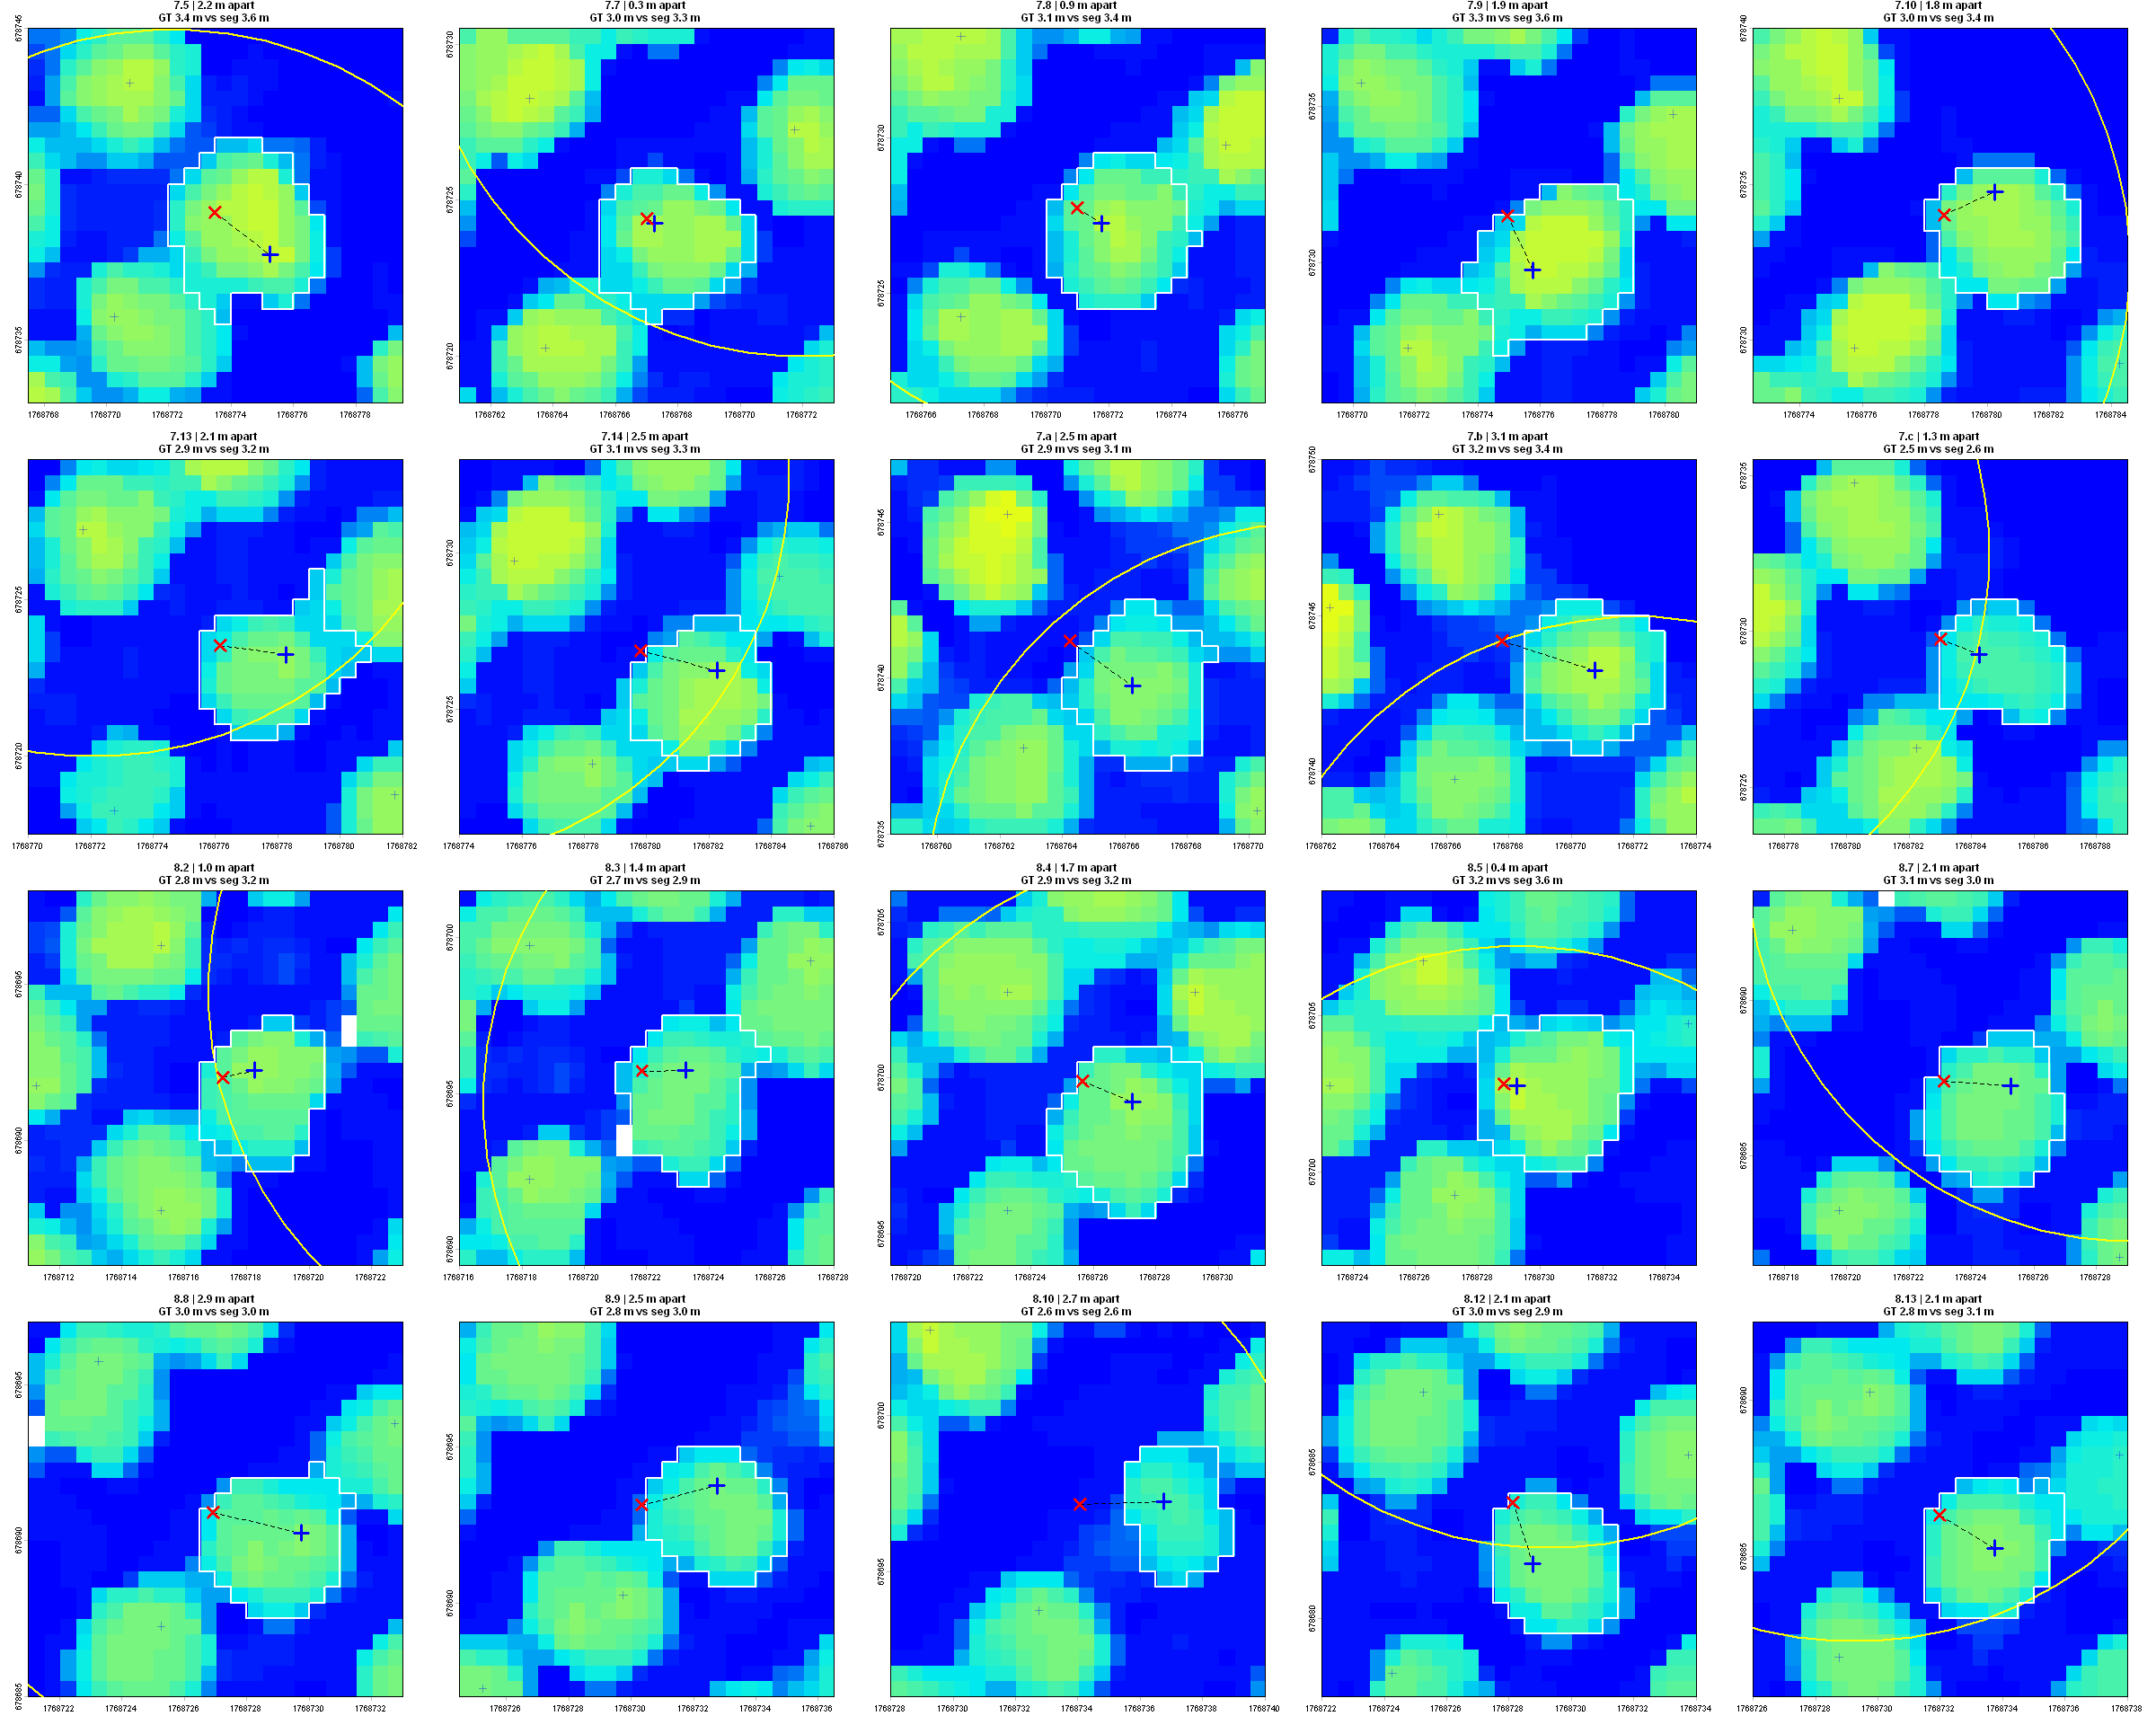

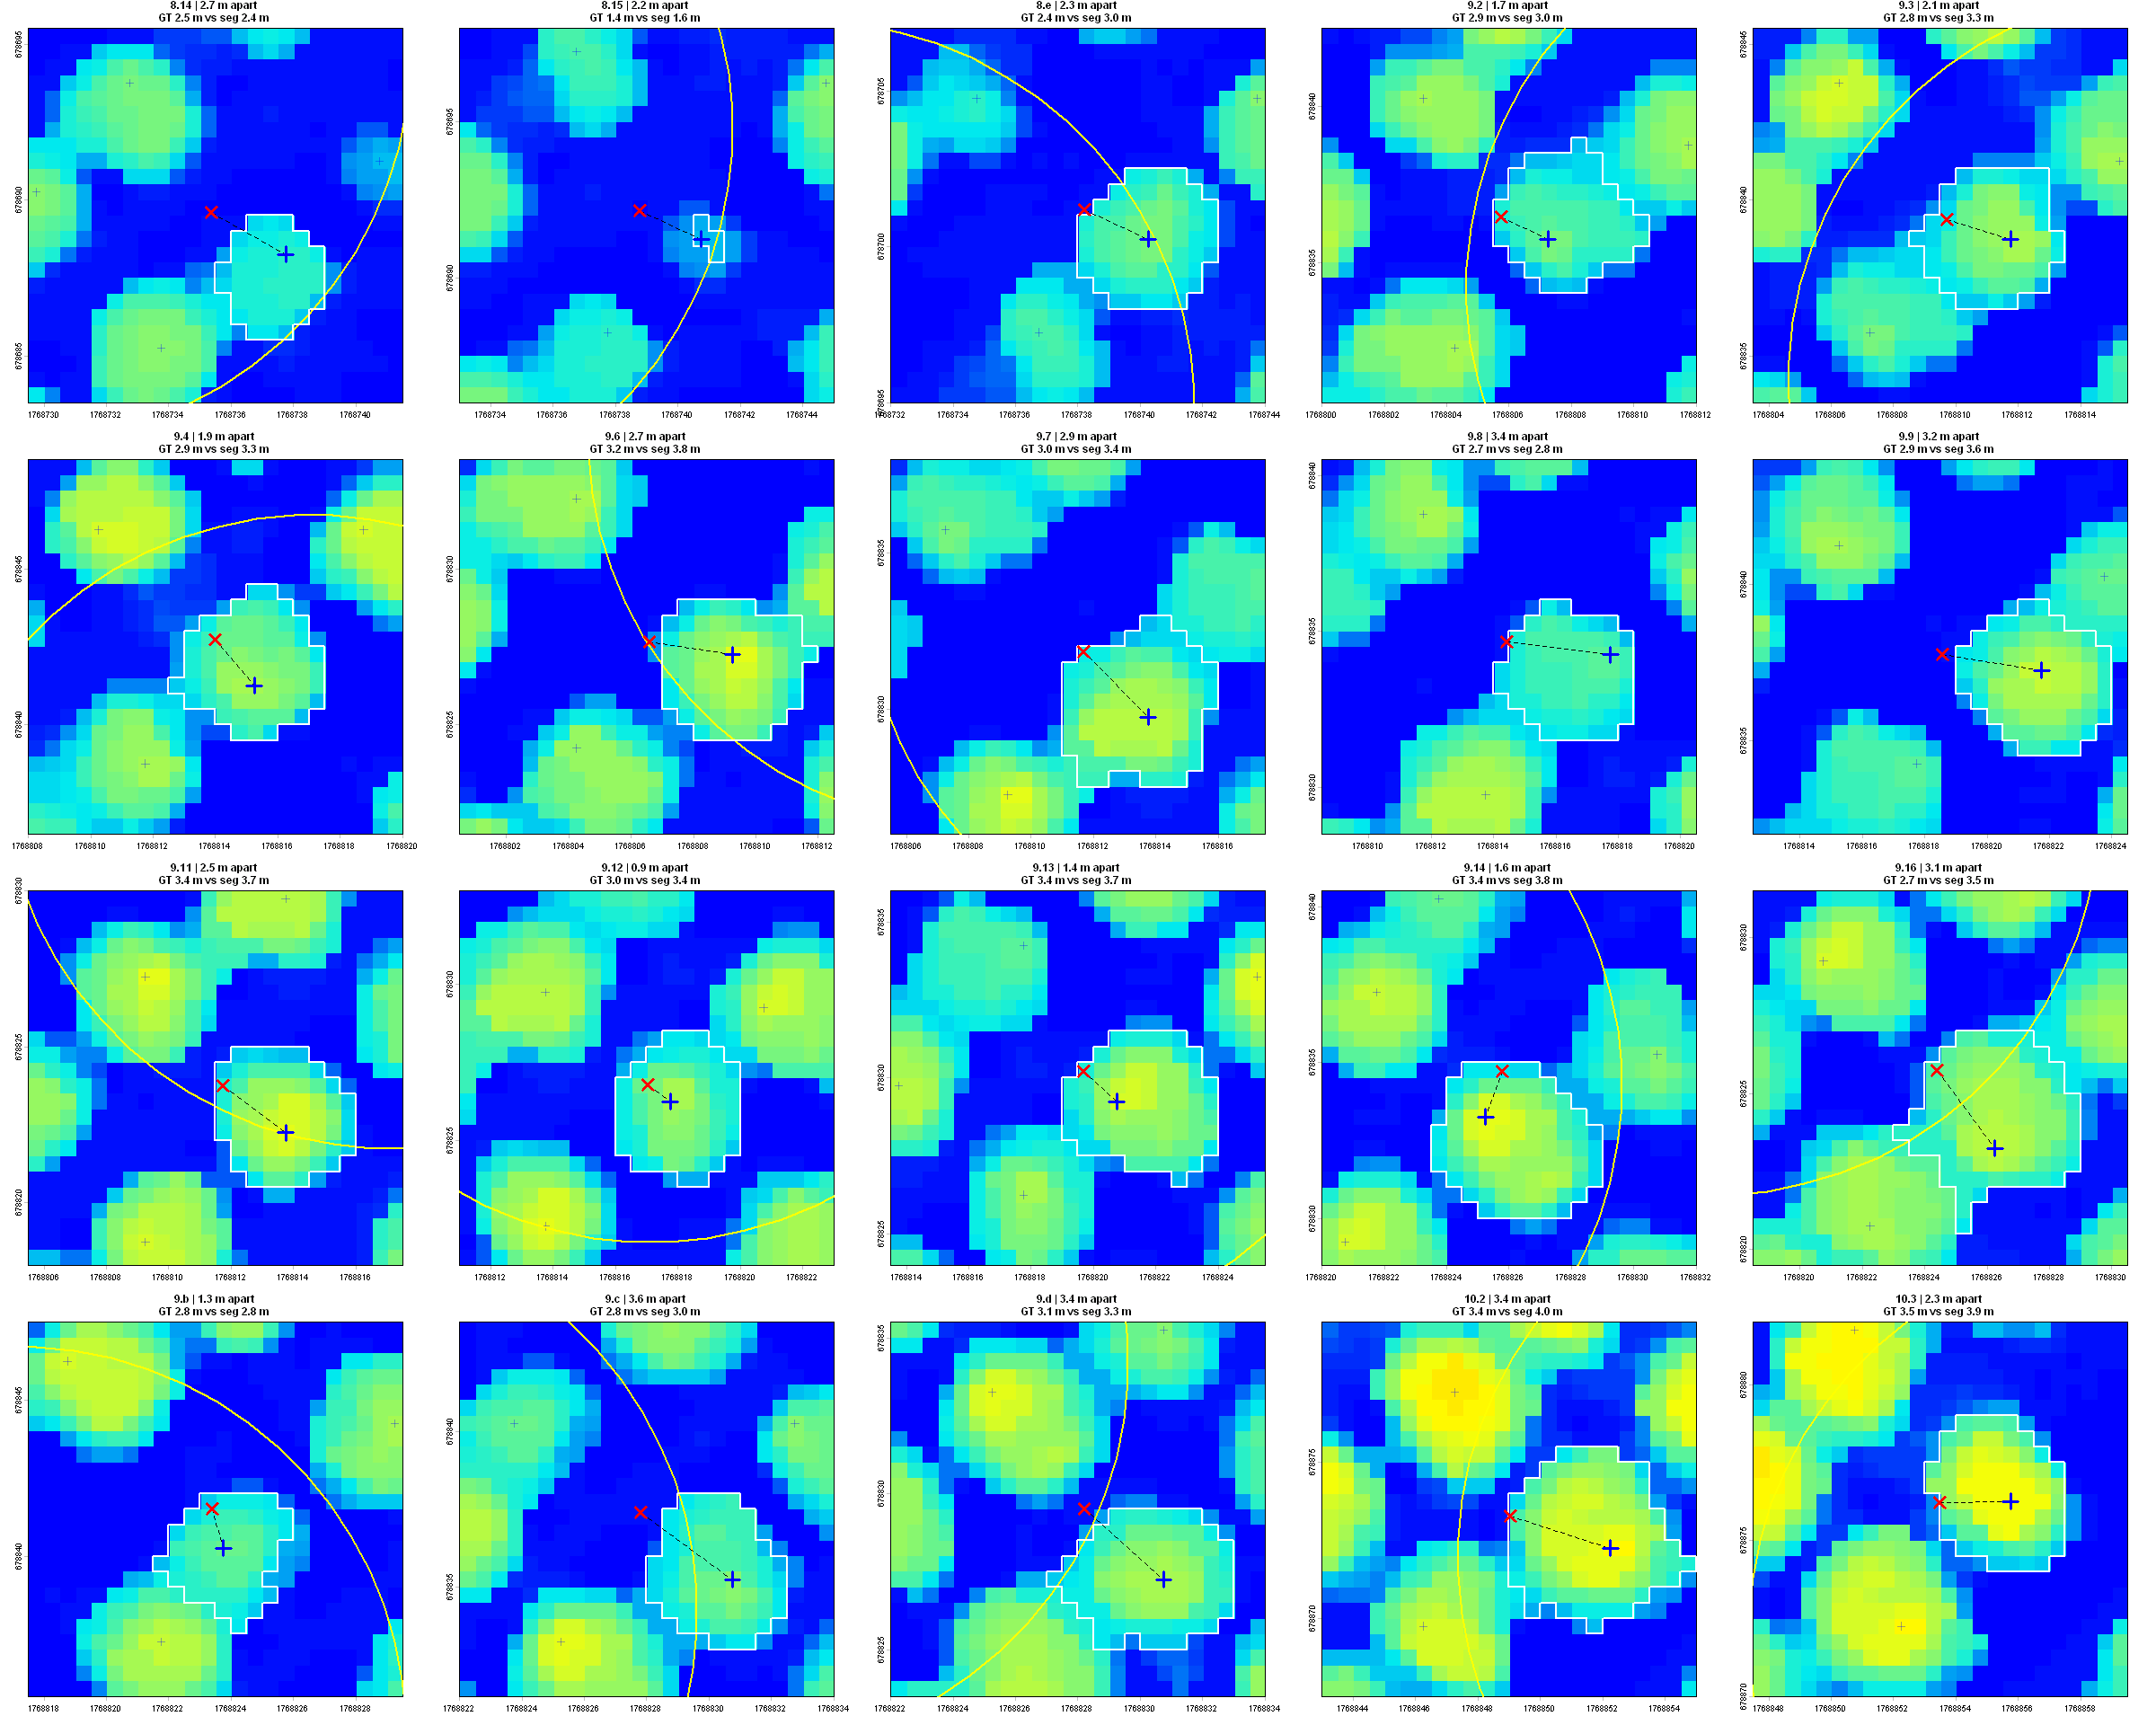

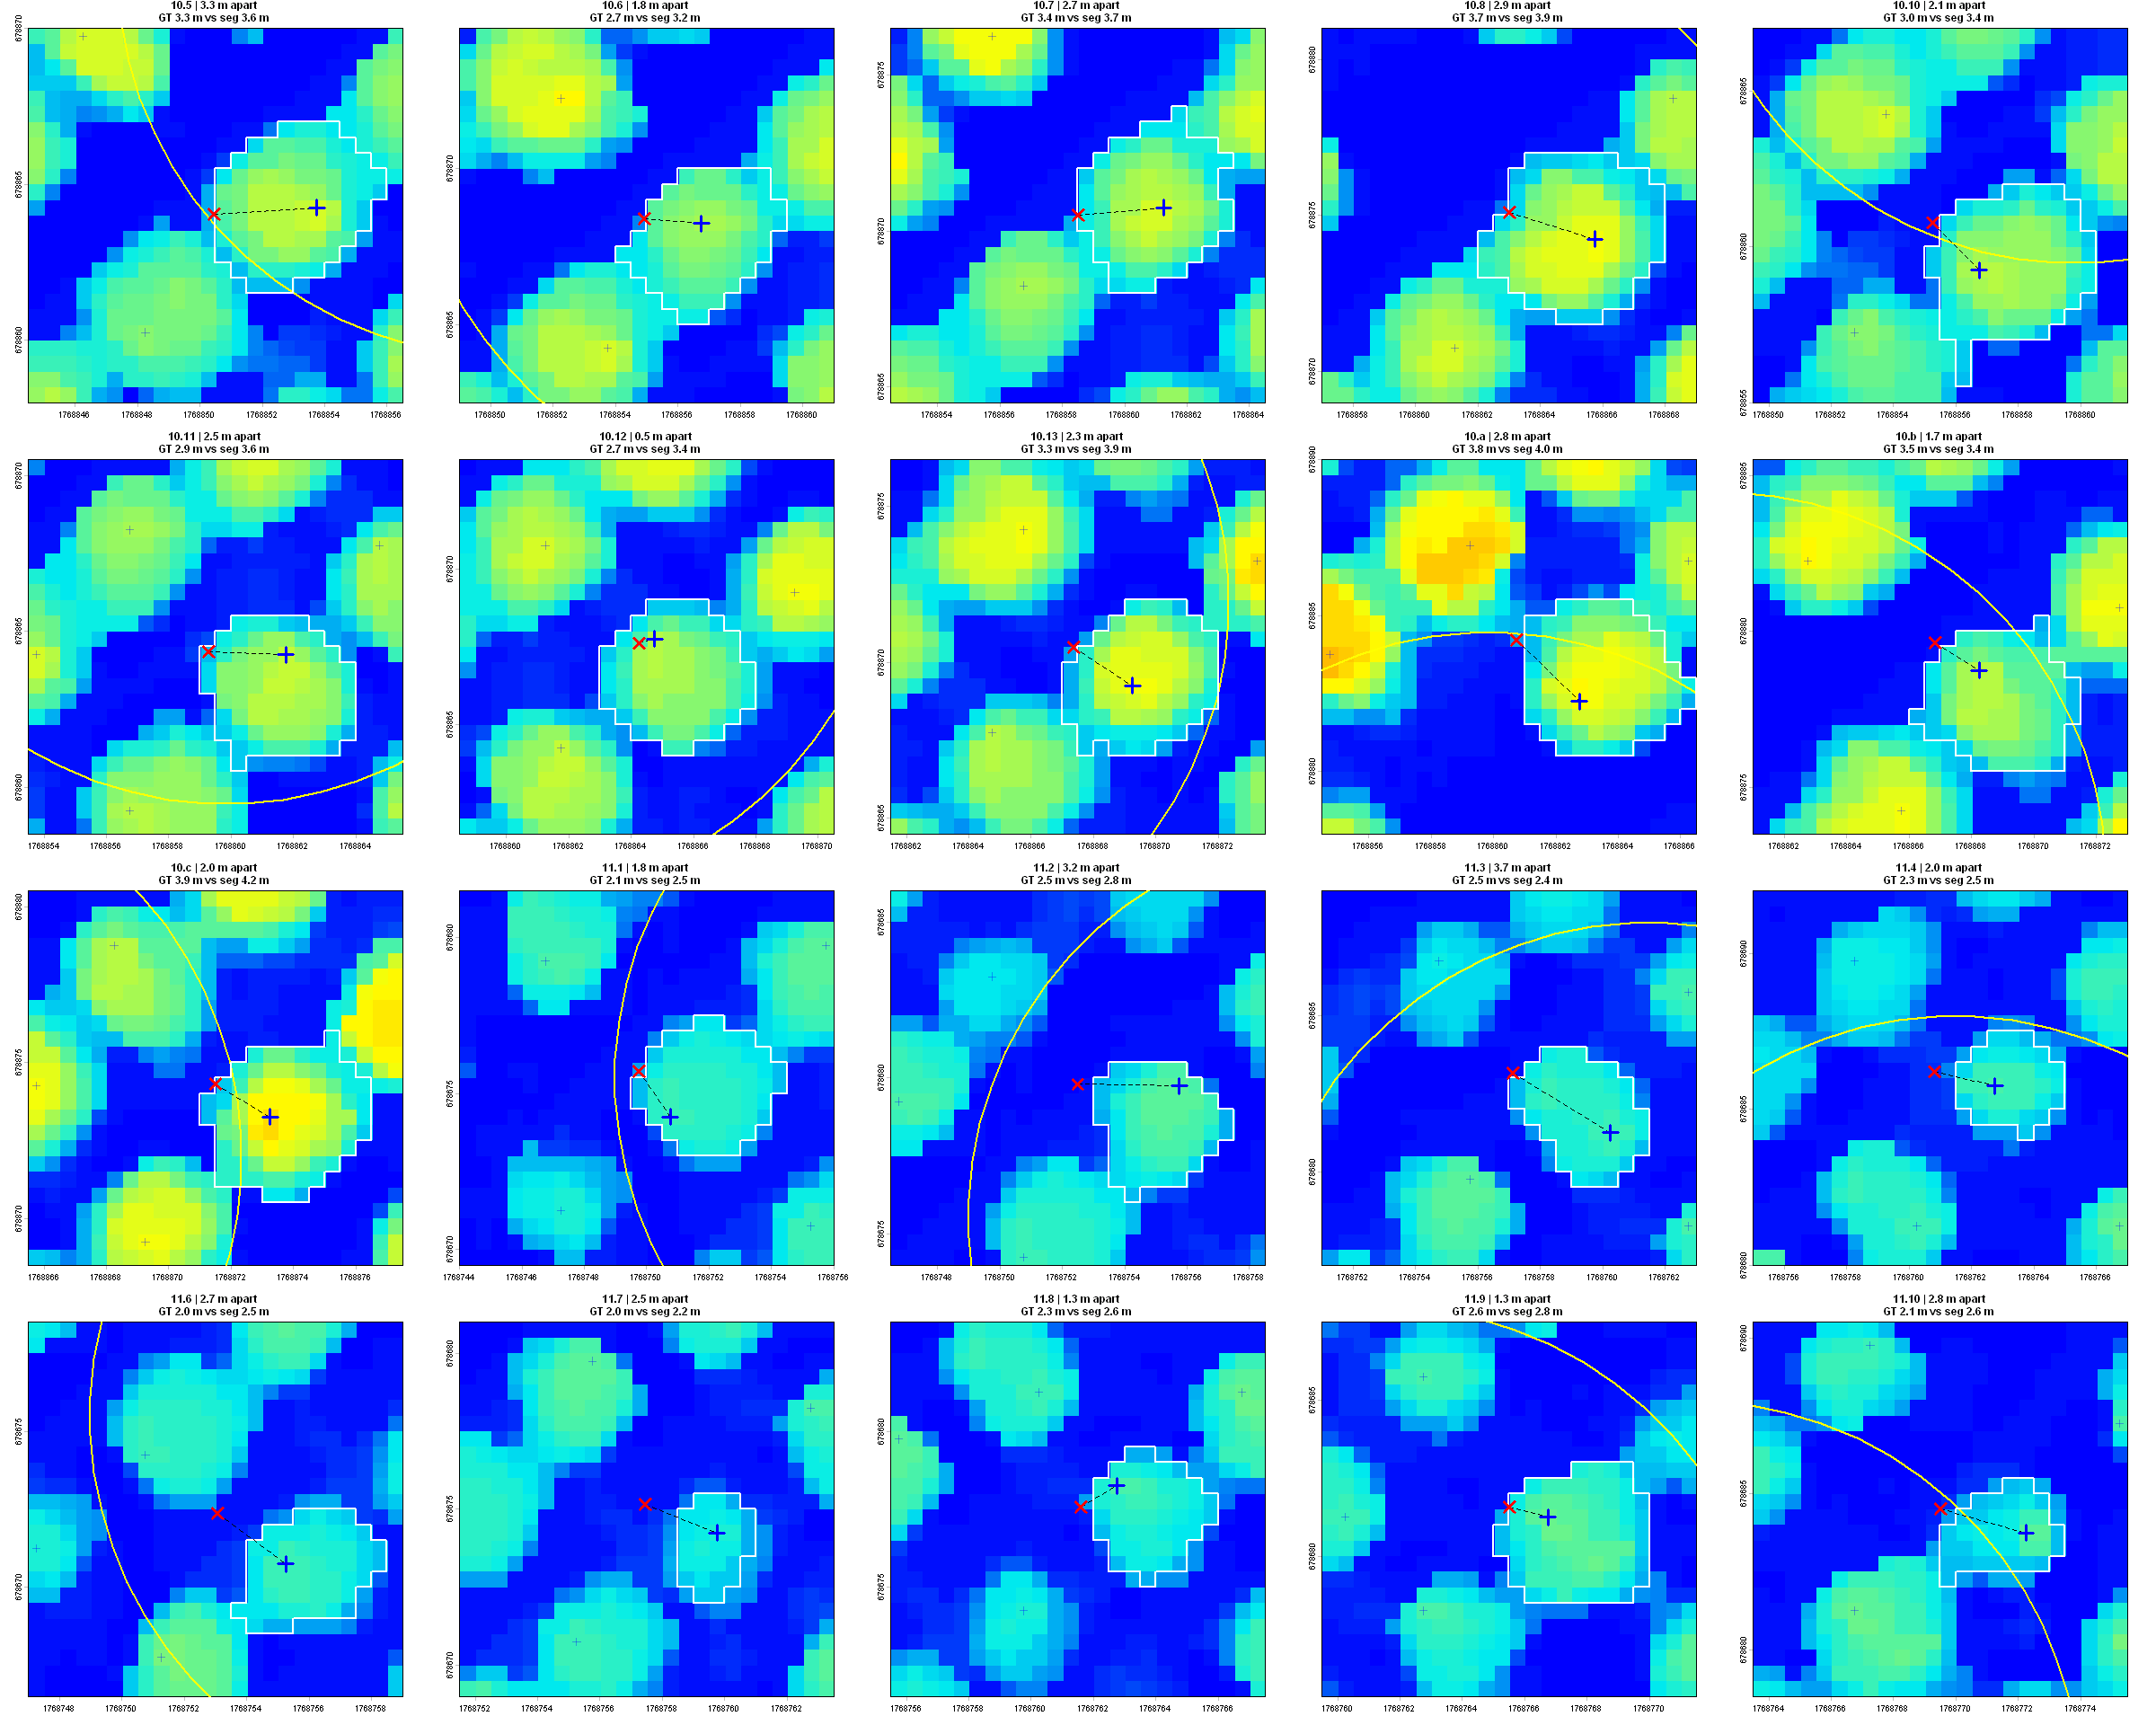

In [13]:
half <- 6            # half-width of each zoom window (m)
n_per_page <- 20     # panels per figure (4 x 5)
cmp_plot <- comparison[!is.na(comparison$gt_x), ]

for (pg in split(seq_len(nrow(cmp_plot)), ceiling(seq_len(nrow(cmp_plot)) / n_per_page))) {
  options(repr.plot.width = 20, repr.plot.height = 16)
  par(mfrow = c(4, 5), mar = c(2, 2, 3, 1))
  for (i in pg) {
    r <- cmp_plot[i, ]
    e <- ext(r$gt_x - half, r$gt_x + half, r$gt_y - half, r$gt_y + half)
    bb <- st_bbox(c(xmin = xmin(e), xmax = xmax(e), ymin = ymin(e), ymax = ymax(e)), crs = st_crs(ttops))

    ttl <- if (r$matched) sprintf("%s | %.1f m apart\nGT %.1f m vs seg %.1f m", r$label, r$dist_m, r$gt_height_m, r$seg_height_m)
           else           sprintf("%s | NO MATCH within %.1f m\nGT %.1f m", r$label, cfg$match_max_dist, r$gt_height_m)
    plot(crop(chm_smooth, e), col = height.colors(50), range = c(0, 6), legend = FALSE, main = ttl, cex.main = 0.9)

    # other treetops in the window (faint), matched crown outline
    tt_w <- ttops[st_intersects(ttops, st_as_sfc(bb), sparse = FALSE)[, 1], ]
    plot(st_geometry(tt_w), add = TRUE, pch = 3, col = adjustcolor("blue", 0.35))
    plot(st_geometry(footprints), border = "yellow", col = NA, lwd = 2, add = TRUE)   # GEDI footprint
    if (r$matched) {
      plot(st_geometry(polys[polys$treeID == r$seg_treeID, ]), border = "white", col = NA, lwd = 2, add = TRUE)
      segments(r$gt_x, r$gt_y, r$seg_x, r$seg_y, col = "black", lty = 2)
      points(r$seg_x, r$seg_y, pch = 3, col = "blue", lwd = 3, cex = 2)      # segmented treetop
    }
    points(r$gt_x, r$gt_y, pch = 4, col = "red", lwd = 3, cex = 2)        # ground-measured location
  }
  par(mfrow = c(1, 1))
}

In [ ]:
fp_rename <- c("9" = 1, "10" = 2, "8" = 3, "7" = 4, "6" = 5, "5" = 6, "11" = 7, "12" = 8, "3" = 9, "4" = 10)   # old footprint label -> new title number

plot_label_group <- function(prefix, pad = 8) {
  g <- comparison[!is.na(comparison$gt_x) & grepl(paste0("^", prefix, "\\."), comparison$label), ]
  if (!nrow(g)) return(invisible(NULL))

  e  <- ext(min(g$gt_x) - pad, max(g$gt_x) + pad, min(g$gt_y) - pad, max(g$gt_y) + pad)
  bb <- st_bbox(c(xmin = xmin(e), xmax = xmax(e), ymin = ymin(e), ymax = ymax(e)), crs = st_crs(ttops))

  options(repr.plot.width = 14, repr.plot.height = 12)
  plot(crop(chm_smooth, e), col = height.colors(50), range = c(0, 6),
       main = sprintf("Footprint %d: ground-measured (red X) vs segmented treetop (blue +)", fp_rename[[as.character(prefix)]]))

  tt_w <- ttops[st_intersects(ttops, st_as_sfc(bb), sparse = FALSE)[, 1], ]
  plot(st_geometry(tt_w), add = TRUE, pch = 3, col = adjustcolor("blue", 0.3))
  plot(st_geometry(polys[polys$treeID %in% g$seg_treeID, ]), border = "white", col = NA, lwd = 2, add = TRUE)
  plot(st_geometry(footprints), border = "yellow", col = NA, lwd = 2, add = TRUE)

  m <- g[g$matched, ]
  segments(m$gt_x, m$gt_y, m$seg_x, m$seg_y, col = "black", lwd = 1.5)
  points(m$seg_x, m$seg_y, pch = 3, col = "blue", lwd = 3, cex = 1.5)
  points(g$gt_x, g$gt_y, pch = 4, col = "red", lwd = 3, cex = 1.5)
  text(g$gt_x, g$gt_y, g$label, pos = 3, col = "white", cex = 1, font = 2)

  legend("topright", legend = c("Ground-measured", "Segmented treetop", "Other treetops", "Matched crown", "GEDI footprint"),
         pch = c(4, 3, 3, NA, NA), col = c("red", "blue", adjustcolor("blue", 0.3), "white", "yellow"),
         lty = c(NA, NA, NA, 1, 1), lwd = c(3, 3, 1, 2, 2), bg = "white")
}

for (p in names(sort(fp_rename))) plot_label_group(as.numeric(p))

## 9. Distributions

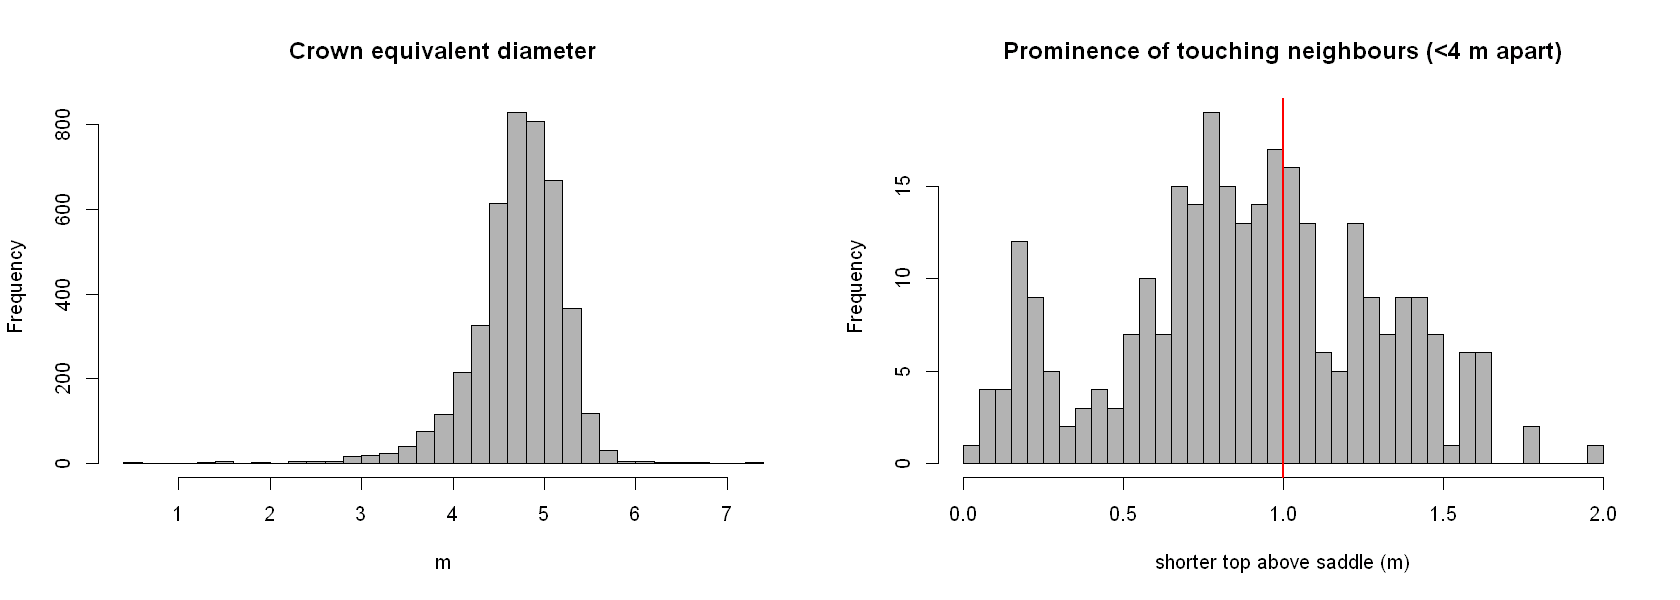

In [15]:
options(repr.plot.width = 14, repr.plot.height = 5)
par(mfrow = c(1, 2))
hist(polys$diam_m, breaks = 40, col = "grey70", main = "Crown equivalent diameter", xlab = "m")
hist(pairs$prominence[pairs$dist_m < cfg$os_max_dist], breaks = 40, col = "grey70",
     main = paste0("Prominence of touching neighbours (<", cfg$os_max_dist, " m apart)"),
     xlab = "shorter top above saddle (m)")
abline(v = cfg$os_min_prom, col = "red", lwd = 2)
par(mfrow = c(1, 1))

## 10. Export

In [16]:
tree_data <- data.frame(treeID = ttops$treeID, x = st_coordinates(ttops)[, "X"],
                        y = st_coordinates(ttops)[, "Y"], height_m = ttops$height) |>
  left_join(st_drop_geometry(polys) |> select(treeID, crown_area_m2 = area_m2, crown_diam_m = diam_m, flag), by = "treeID")
write.csv(tree_data, file.path(out_dir, "tree_heights.csv"), row.names = FALSE)
st_write(polys, file.path(out_dir, "crowns.gpkg"), delete_dsn = TRUE, quiet = TRUE)
st_write(ttops, file.path(out_dir, "treetops.gpkg"), delete_dsn = TRUE, quiet = TRUE)
cat("Saved to", normalizePath(out_dir), "\n")

Saved to C:\Users\kdavis99\OneDrive - Cal Poly\Tree Biomass Estimation Research - Documents\GitHub_Repository\Biomass_Monitoring_Research\outputs\Bartleson Tree Segmentation\watershed_0.5m 
